<a href="https://colab.research.google.com/github/rapiissan/Telco-Customer-Churn-Analysis/blob/main/Raffy_Ikhsan_Maulana_EDA_Telco_Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploratory Data analysis**
## **Case - Telco Customer Churn**

## **1. Business Understanding**

### Konteks Customer Churn
Sebuah perusahaan telekomunikasi (seperti penyedia layanan internet kabel, telepon rumah, dan TV berlangganan) menjalankan bisnisnya, salah satu tantangan terbesar yang dihadapi adalah risiko pelanggan **berhenti berlangganan atau berpindah ke kompetitor.** Risiko ini disebut **churn.** Mengakuisisi pelanggan baru (customer acquisition) membutuhkan biaya pemasaran dan operasional yang jauh lebih tinggi daripada mempertahankan pelanggan yang sudah ada (customer retention). Oleh karena itu, perusahaan perlu memahami karakteristik pelanggan dan pola penggunaan layanan yang berasosiasi dengan risiko churn yang lebih tinggi, agar tindakan pencegahan bisa dilakukan lebih awal dan terukur.

Dataset ini berisi data historis pelanggan, mencakup profil demografis pelanggan (jenis kelamin, lansia, status pasangan, tanggungan keluarga), karakteristik layanan yang dipakai (layanan telepon, jenis internet wifi, proteksi digital, streaming), lama berlangganan (tenure), jenis kontrak, metode pembayaran, serta rincian biaya tagihan (biaya bulanan dan total biaya).

### Tujuan Analisis

Tujuan dari EDA ini adalah untuk **memahami data** secara mendalam dan **menemukan pola-pola awal** terkait perilaku pelanggan yang berisiko pergi (churn).

### Target Variabel
`churn` — variabel biner yang menandakan status kelangsungan langganan pelanggan:
- `0` = Bertahan / kondisi di mana pelanggan **tetap** setia menggunakan layanan perusahaan telekomunikasi.

- `1` = Churn / kondisi di mana pelanggan memutuskan untuk **berhenti** berlangganan dan berhenti menggunakan layanan.

### Contoh Pertanyaan Analisis
1. Bagaimana karakteristik umum profil demografis pelanggan dalam dataset ini (proporsi lansia, jenis kelamin, dan kepemilikan tanggungan keluarga)?
2. Bagaimana distribusi risiko kehilangan pelanggan (proporsi pelanggan yang churn vs pelanggan yang bertahan)?
3. Fitur utama apa saja (baik numerik seperti tenure dan biaya bulanan, maupun kategorikal seperti jenis kontrak, layanan internet, dan metode pembayaran) yang menunjukkan pola paling kontras membedakan kelompok churn dan bertahan?
4. Apakah terdapat hubungan yang kuat antar variabel finansial pelanggan (misalnya antara lama berlangganan/tenure, biaya bulanan/MonthlyCharges, dan akumulasi biaya/TotalCharges)?
5. Masalah kualitas data apa saja (seperti ketidaksesuaian tipe data dan adanya nilai kosong/spasi pada pelanggan baru) yang harus dibersihkan sebelum data digunakan ke tahap pemodelan Machine Learning?

## **2. Data Understanding/Gambaran Dataset**
Sebelum menganalisis pola dari suatu data, langkah pertama adalah memahami apa yang direpresentasikan oleh setiap kolom pada dataset.

In [ ]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
df = pd.read_csv(url)

# Konfigurasi tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.figsize'] = (8, 5)

RANDOM_STATE = 42

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### **Makna Kolom**

> Tambahkan blockquote

| No | Kolom | Makna |
|---|---|---|
| 1 | `customerID` | Nomor ID unik berbentuk teks & angka untuk setiap pelanggan. |
| 2 | `gender` | Jenis kelamin pelanggan (Female / Male). |  
| 3 | `SeniorCitizen`| Status apakah pelanggan merupakan lansia atau tidak (1 = Lansia, 0 = Bukan Lansia). |  
| 4 | `Partner`| Apakah pelanggan memiliki pasangan hidup/menikah. |
| 5 | `Dependents` | Apakah pelanggan memiliki tanggungan finansial di rumahnya, seperti anak atau orang tua.|
| 6 | `tenure` | Durasi atau lama waktu (dalam hitungan bulan) pelanggan tersebut sudah berlangganan di perusahaan. |
| 7 | `PhoneService` | Apakah pelanggan berlangganan layanan telepon rumah. |
| 8 | `MultipleLines` |Apakah pelanggan memiliki lebih dari satu saluran telepon rumah.|
| 9 | `InternetService` |Jenis teknologi internet Wifi yang digunakan (DSL, Fiber optic, atau No).|
| 10 | `OnlineSecurity` |Layanan keamanan digital/antivirus dari perusahaan.|
| 11 | `OnlineBackup` |Layanan penyimpanan data online/cloud backup.|
| 12 | `DeviceProtection` |Layanan asuransi untuk proteksi kerusakan perangkat/modem.|
| 13 | `TechSupport` |Layanan bantuan teknisi prioritas jika ada gangguan.|
| 14 | `StreamingTV` |Paket langganan untuk menonton siaran TV kabel.|
| 15 | `StreamingMovies` |Paket langganan untuk menonton film bioskop.|
| 16 | `Contact` |Jenis jangka waktu kontrak berlangganan. |
| 17 | `PaperlessBilling` |Apakah tagihan dikirim secara digital tanpa kertas, misalnya lewat email.|
| 18 | `PaymentMethod` |Metode yang digunakan pelanggan untuk membayar tagihan bulanan. |
| 19 | `MonthlyCharges` |Besar biaya tagihan bulanan yang harus dibayar pelanggan saat ini.|
| 20 | `TotalCharges` | Total akumulasi uang yang sudah dibayarkan pelanggan sejak pertama kali mendaftar hingga sekarang.|
| 21 | `Churn` |Status apakah pelanggan tersebut berhenti berlangganan atau tidak.|


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Interpretasi:**
* Dataset memiliki 7042 baris dengan 21 kolom
* Dataset terdiri dari kombinasi tipe numerik (`int64`, `float64`) dan kategorikal (`object`).
* Salah satu kolom numerik: `TotalCharges` non-null lebih kecil dari total baris, mengindikasikan adanya **missing values**.

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


**Interpretasi awal dari statistik deskriptif:**
- `SeniorCitizen` merupakan status pelanggan apakah termasuk lanjut usia atau bukan, sehingga perhitungan seperti **_mean, std, min, 25%, 50%, 75%, dan max_** tidak perlu dihiraukan berapapun nilainya.
- `TotalCharges` memiliki missing value sebanyak **11 data**, sehingga data yang terisi atau memiliki value hanya **7032** dari **7043** banyaknya data.
- `TotalCharges` memiliki rentang yang sangat lebar (dari 18 hingga lebih dari 8 ribu), dengan mean yang lebih besar dibanding dari median — indikasi **distribusi yang sangat right-skewed** (data dengan nilai tinggi lebih banyak dibanding nilai rendah).
- `MonthlyCharges` memiliki persebaran data yang cukup stabil, terlihat pada **nilai kuartil bawah, kuartil tengah/median, dan kuartil atas** yang tergolong stabil.



In [ ]:
print("Jumlah unique value per kolom:")
df.nunique().sort_values()

Jumlah unique value per kolom:


,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


**Interpretasi:**
* Kolom `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, hingga `PaymentMethod` memiliki jumlah unique value yang kecil (2-4), konsisten dengan sifatnya sebagai variabel kategorikal/biner
* Kolom `tenure`, `MonthlyCharges`, dan `TotalCharges` memiliki ratusan hingga ribuan unique value, konsisten dengan sifatnya sebagai variabel numerik kontinu.
* Kolom `customerID` memiliki 7.043 unique value. Karena fungsinya hanya sebagai identifier unik (string) dan bukan prediktor, kolom ini harus di-drop sebelum masuk ke tahap modeling.

**Interpretasi:** Dataset memiliki 4 fitur numerik, 16 fitur kategorikal, dan 1 target variable biner (`Churn`).

# **3. Data Cleaning**
## **3.1 Memeriksa _Missing Value_**


In [ ]:
missing = pd.DataFrame({
    "Tipe Data": df.dtypes,
    "Banyak Missing": df.isna().sum(),
    "Persentase Missing": (df.isna().mean() * 100).round(2),
    "Banyak Unique Value": df.nunique()
})

missing.sort_values("Banyak Missing", ascending=False)


,Tipe Data,Banyak Missing,Persentase Missing,Banyak Unique Value
TotalCharges,float64,11,0.16,6530
gender,object,0,0.00,2
SeniorCitizen,int64,0,0.00,2
Partner,object,0,0.00,2
customerID,object,0,0.00,7043
Dependents,object,0,0.00,2
tenure,int64,0,0.00,73
MultipleLines,object,0,0.00,3
PhoneService,object,0,0.00,2
OnlineSecurity,object,0,0.00,3


In [ ]:
df_missing = df[df['TotalCharges'].isna()]
display(df_missing[["Contract","tenure","TotalCharges","MonthlyCharges","Churn"]])

,Contract,tenure,TotalCharges,MonthlyCharges,Churn
488,Two year,0,NaN,52.55,No
753,Two year,0,NaN,20.25,No
936,Two year,0,NaN,80.85,No
1082,Two year,0,NaN,25.75,No
1340,Two year,0,NaN,56.05,No
3331,Two year,0,NaN,19.85,No
3826,Two year,0,NaN,25.35,No
4380,Two year,0,NaN,20.00,No
5218,One year,0,NaN,19.70,No
6670,Two year,0,NaN,73.35,No


**Interpretasi:** Dari 21 fitur yang ada, Missing value ditemukan pada fitur `TotalCharges` sebanyak **11 dari 7042** pelanggan, persentase missing value sebesar **0.16%**. Missing value pada kolom `TotalCharges` ditemukan pada pelanggan dengan `tenure` sebesar 0 bulan. Hal ini mengindikasikan bahwa pelanggan tersebut baru mulai berlangganan sehingga belum memiliki akumulasi biaya langganan.

## **3.2 Memeriksa Data Duplikat**

In [ ]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv")  # sesuaikan dengan datasetmu

jumlah_dup = df.duplicated().sum()
persen_dup = jumlah_dup / len(df) * 100

print(f"Baris duplikat : {jumlah_dup}")
print(f"Persentase     : {persen_dup:.2f}%")

Baris duplikat : 0
Persentase     : 0.00%


**Interpretasi:** Berdasarkan hasil pemeriksaan, tidak ditemukan adanya data duplikat pada dataset. Hal ini menunjukkan bahwa setiap baris data memiliki kombinasi nilai yang unik sehingga tidak diperlukan proses penghapusan data duplikat.

## **3.3 Memeriksa Outlier**


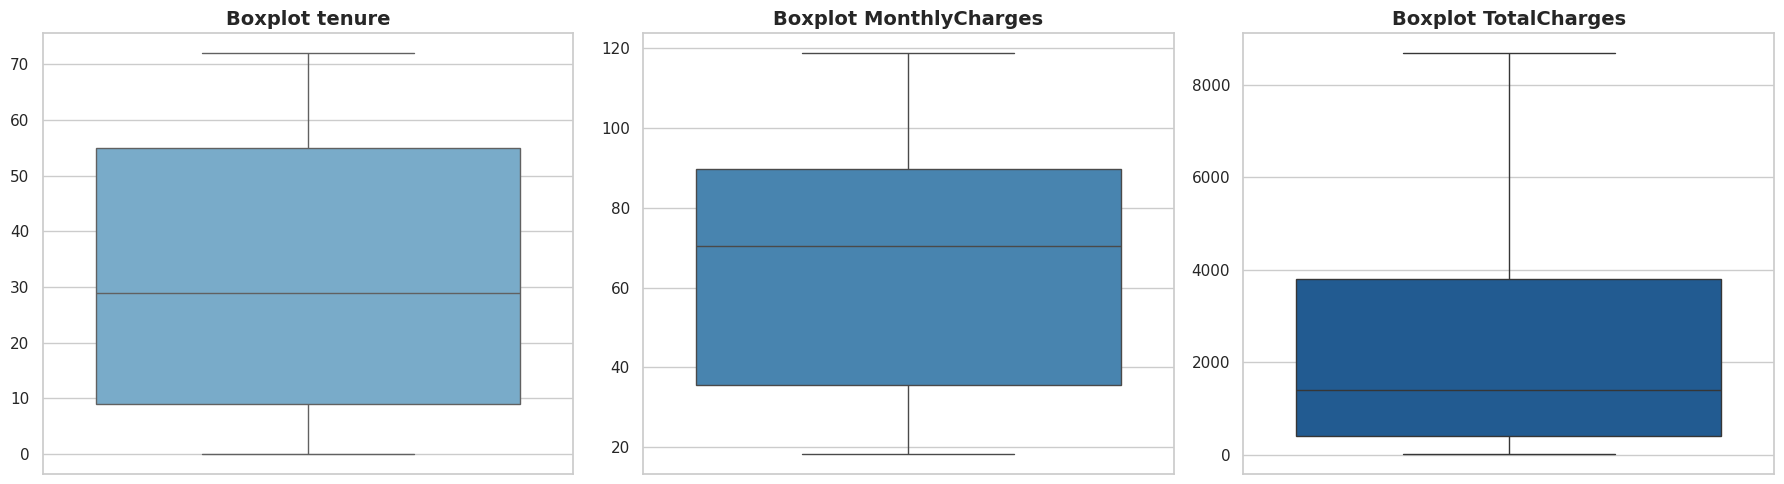

Fitur 'tenure':
  - Batas Bawah (Lower Bound): -60.00
  - Batas Atas (Upper Bound): 124.00
  - Jumlah Outlier Terdeteksi: 0 dari 7043 data
--------------------------------------------------
Fitur 'MonthlyCharges':
  - Batas Bawah (Lower Bound): -46.02
  - Batas Atas (Upper Bound): 171.38
  - Jumlah Outlier Terdeteksi: 0 dari 7043 data
--------------------------------------------------
Fitur 'TotalCharges':
  - Batas Bawah (Lower Bound): -4688.48
  - Batas Atas (Upper Bound): 8884.67
  - Jumlah Outlier Terdeteksi: 0 dari 7032 data
--------------------------------------------------


In [ ]:
# Membuat boxplot dengan variasi warna palet biru untuk mendeteksi outlier
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
# Menggunakan variasi warna biru dari palet seaborn
blue_palette = sns.color_palette("Blues_r", n_colors=5)
colors = [blue_palette[2], blue_palette[1], blue_palette[0]]

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Boxplot {col}', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('')

plt.tight_layout()
plt.show()

# Menghitung jumlah outlier menggunakan metode IQR
for col in num_cols:
    # Menghapus NaN terlebih dahulu agar perhitungan IQR valid
    clean_data = df[col].dropna()
    Q1 = clean_data.quantile(0.25)
    Q3 = clean_data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = clean_data[(clean_data < lower_bound) | (clean_data > upper_bound)]
    print(f"Fitur '{col}':")
    print(f"  - Batas Bawah (Lower Bound): {lower_bound:.2f}")
    print(f"  - Batas Atas (Upper Bound): {upper_bound:.2f}")
    print(f"  - Jumlah Outlier Terdeteksi: {len(outliers)} dari {len(clean_data)} data")
    print("-" * 50)

**Interpretasi:** Berdasarkan hasil identifikasi menggunakan metode *Interquartil Range* (IQR), tidak ditemukan nilai yang terindikasi sebagai *outlier* pada variabel yang dianalisis. Dengan demikian, tidak terdapat indikasi nilai ekstrem berdasarkan kriteria IQR yang memerlukan penanganan khusus pada tahap ini.

## **3.4 Kesalahan *Miss-Understanding* pada sistem**

### **Analisis Fenomena Structural Missingness**

Kita akan memisahkan dan menampilkan sampel baris serta fitur terkait untuk pelanggan yang tidak memiliki layanan telepon (`No phone service`) dan yang tidak memiliki layanan internet (`No internet service`).

In [ ]:
# 1. Menampilkan data pelanggan tanpa layanan telepon (No phone service)
phone_cols = ['PhoneService', 'MultipleLines']
df_no_phone = df[df['MultipleLines'] == 'No phone service']

print(f"Jumlah pelanggan tanpa layanan telepon: {len(df_no_phone)} baris")
display(df_no_phone[phone_cols].head(5))

Jumlah pelanggan tanpa layanan telepon: 682 baris


,PhoneService,MultipleLines
0,No,No phone service
3,No,No phone service
7,No,No phone service
20,No,No phone service
27,No,No phone service


In [ ]:
# 2. Menampilkan data pelanggan tanpa layanan internet (No internet service)
internet_related_cols = [
    'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]
df_no_internet = df[df['InternetService'] == 'No']

print(f"Jumlah pelanggan tanpa layanan internet: {len(df_no_internet)} baris")
display(df_no_internet[internet_related_cols].head(5))

Jumlah pelanggan tanpa layanan internet: 1526 baris


,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
11,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service
16,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service
21,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service
22,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service
33,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service


**Interpretasi:** pada feature `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`,	`TechSupport`, `StreamingTV`, dan `StreamingMovies`. Terdapat value **"No internet service"** yang menunjukkan fenomena ***Structural Missingness*** atau ketergantungan berjenjang. Nilai tidak hanya merepresentasikan status keaktifan fitur, melainkan juga menyerap kondisi dari fitur utama (`MultipleLines`).

#**4. Analisis Target**

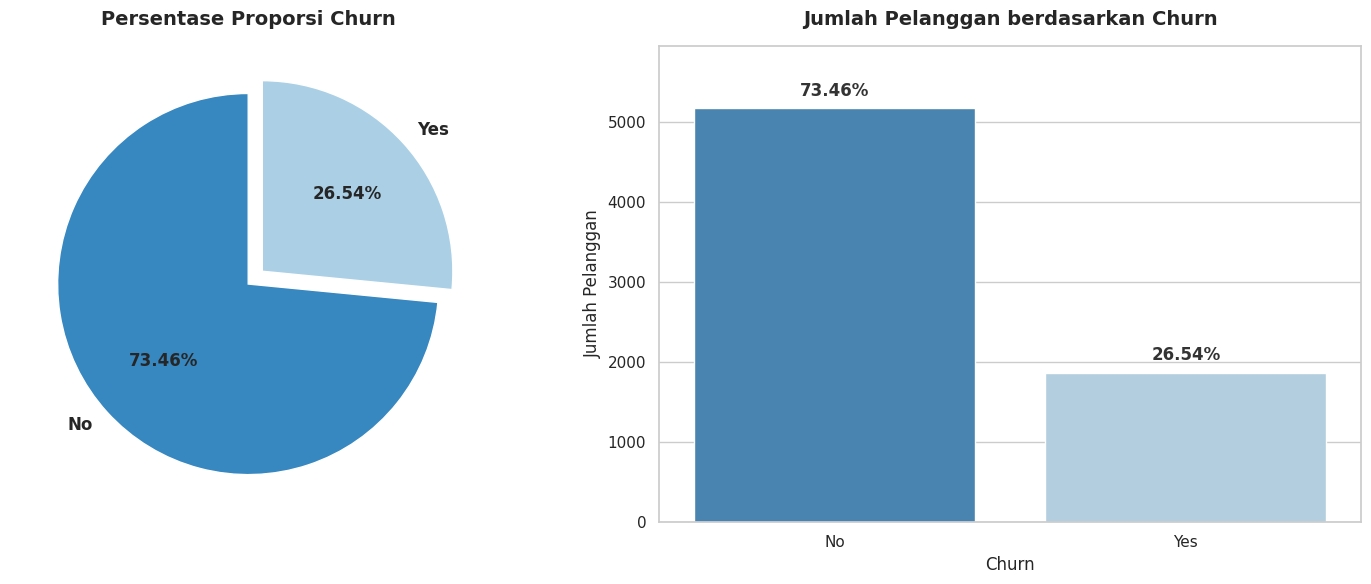

,Jumlah Pelanggan,Persentase (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


In [ ]:
# Visualisasi Target: Gabungan Pie Chart dan Bar Chart (Countplot)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Data Distribusi
churn_counts = df['Churn'].value_counts()
blue_palette = sns.color_palette("Blues_r", n_colors=5)
colors_pie = [blue_palette[1], blue_palette[3]]
colors_bar = [blue_palette[1], blue_palette[3]]

# 1. Pie Chart (Kiri)
axes[0].pie(
    churn_counts,
    labels=churn_counts.index,
    autopct='%1.2f%%',
    startangle=90,
    colors=colors_pie,
    explode=(0, 0.1),
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[0].set_title('Persentase Proporsi Churn', fontsize=14, fontweight='bold', pad=15)

# 2. Bar Chart / Countplot (Kanan)
ax_bar = sns.countplot(
    data=df,
    x='Churn',
    order=churn_counts.index,
    hue='Churn',
    palette=colors_bar,
    ax=axes[1],
    legend=False
)

# Menambahkan label persentase di atas setiap bar
total = len(df['Churn'])
for p in ax_bar.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.2f}%'
    ax_bar.annotate(percentage,
                    (p.get_x() + p.get_width() / 2., height + (total * 0.015)),
                    ha='center', va='bottom', fontsize=12, fontweight='bold', color='#333333')

axes[1].set_title('Jumlah Pelanggan berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Churn', fontsize=12)
axes[1].set_ylabel('Jumlah Pelanggan', fontsize=12)
axes[1].set_ylim(0, churn_counts.max() * 1.15)

plt.tight_layout()
plt.show()

# Menampilkan tabel distribusi frekuensi
distribusi_target = pd.DataFrame({
    'Jumlah Pelanggan': churn_counts,
    'Persentase (%)': (df['Churn'].value_counts(normalize=True) * 100).round(2)
})
display(distribusi_target)

**Interpretasi:** Sekitar **73.46% peminjam *"No Churn"***  dan sekitar **22% Yes/Churn**. Ini menunjukkan bahwa dataset **tidak seimbang (imbalanced)**, yakni kelas mayoritas (No Churn) jauh lebih banyak dibanding kelas minoritas (Churn).

# **5. Univariate Analysis**
## **5.1 Fitur Numerik**

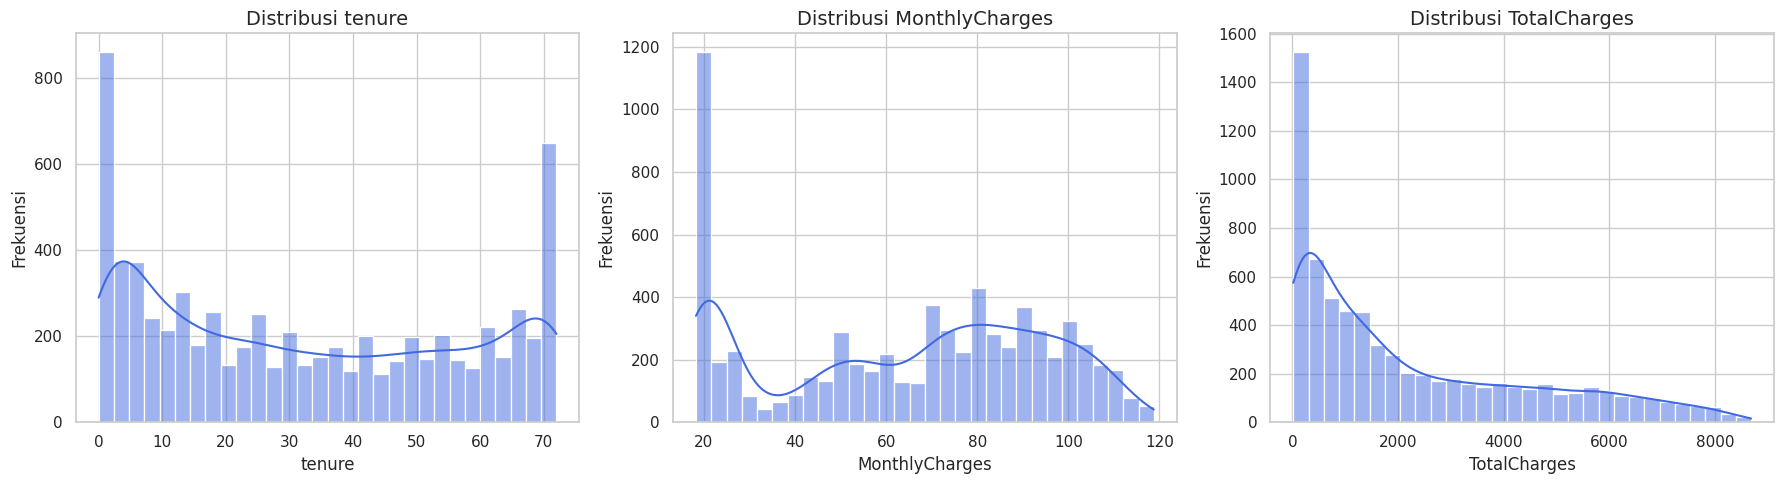

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [ ]:
# Menentukan fitur numerik
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Membuat subplot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(num_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='royalblue', bins=30)
    axes[i].set_title(f'Distribusi {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Frekuensi', fontsize=12)

plt.tight_layout()
plt.show()

# Menampilkan statistik deskriptif
display(df[num_features].describe())

## **5.2 Fitur Kategorikal**

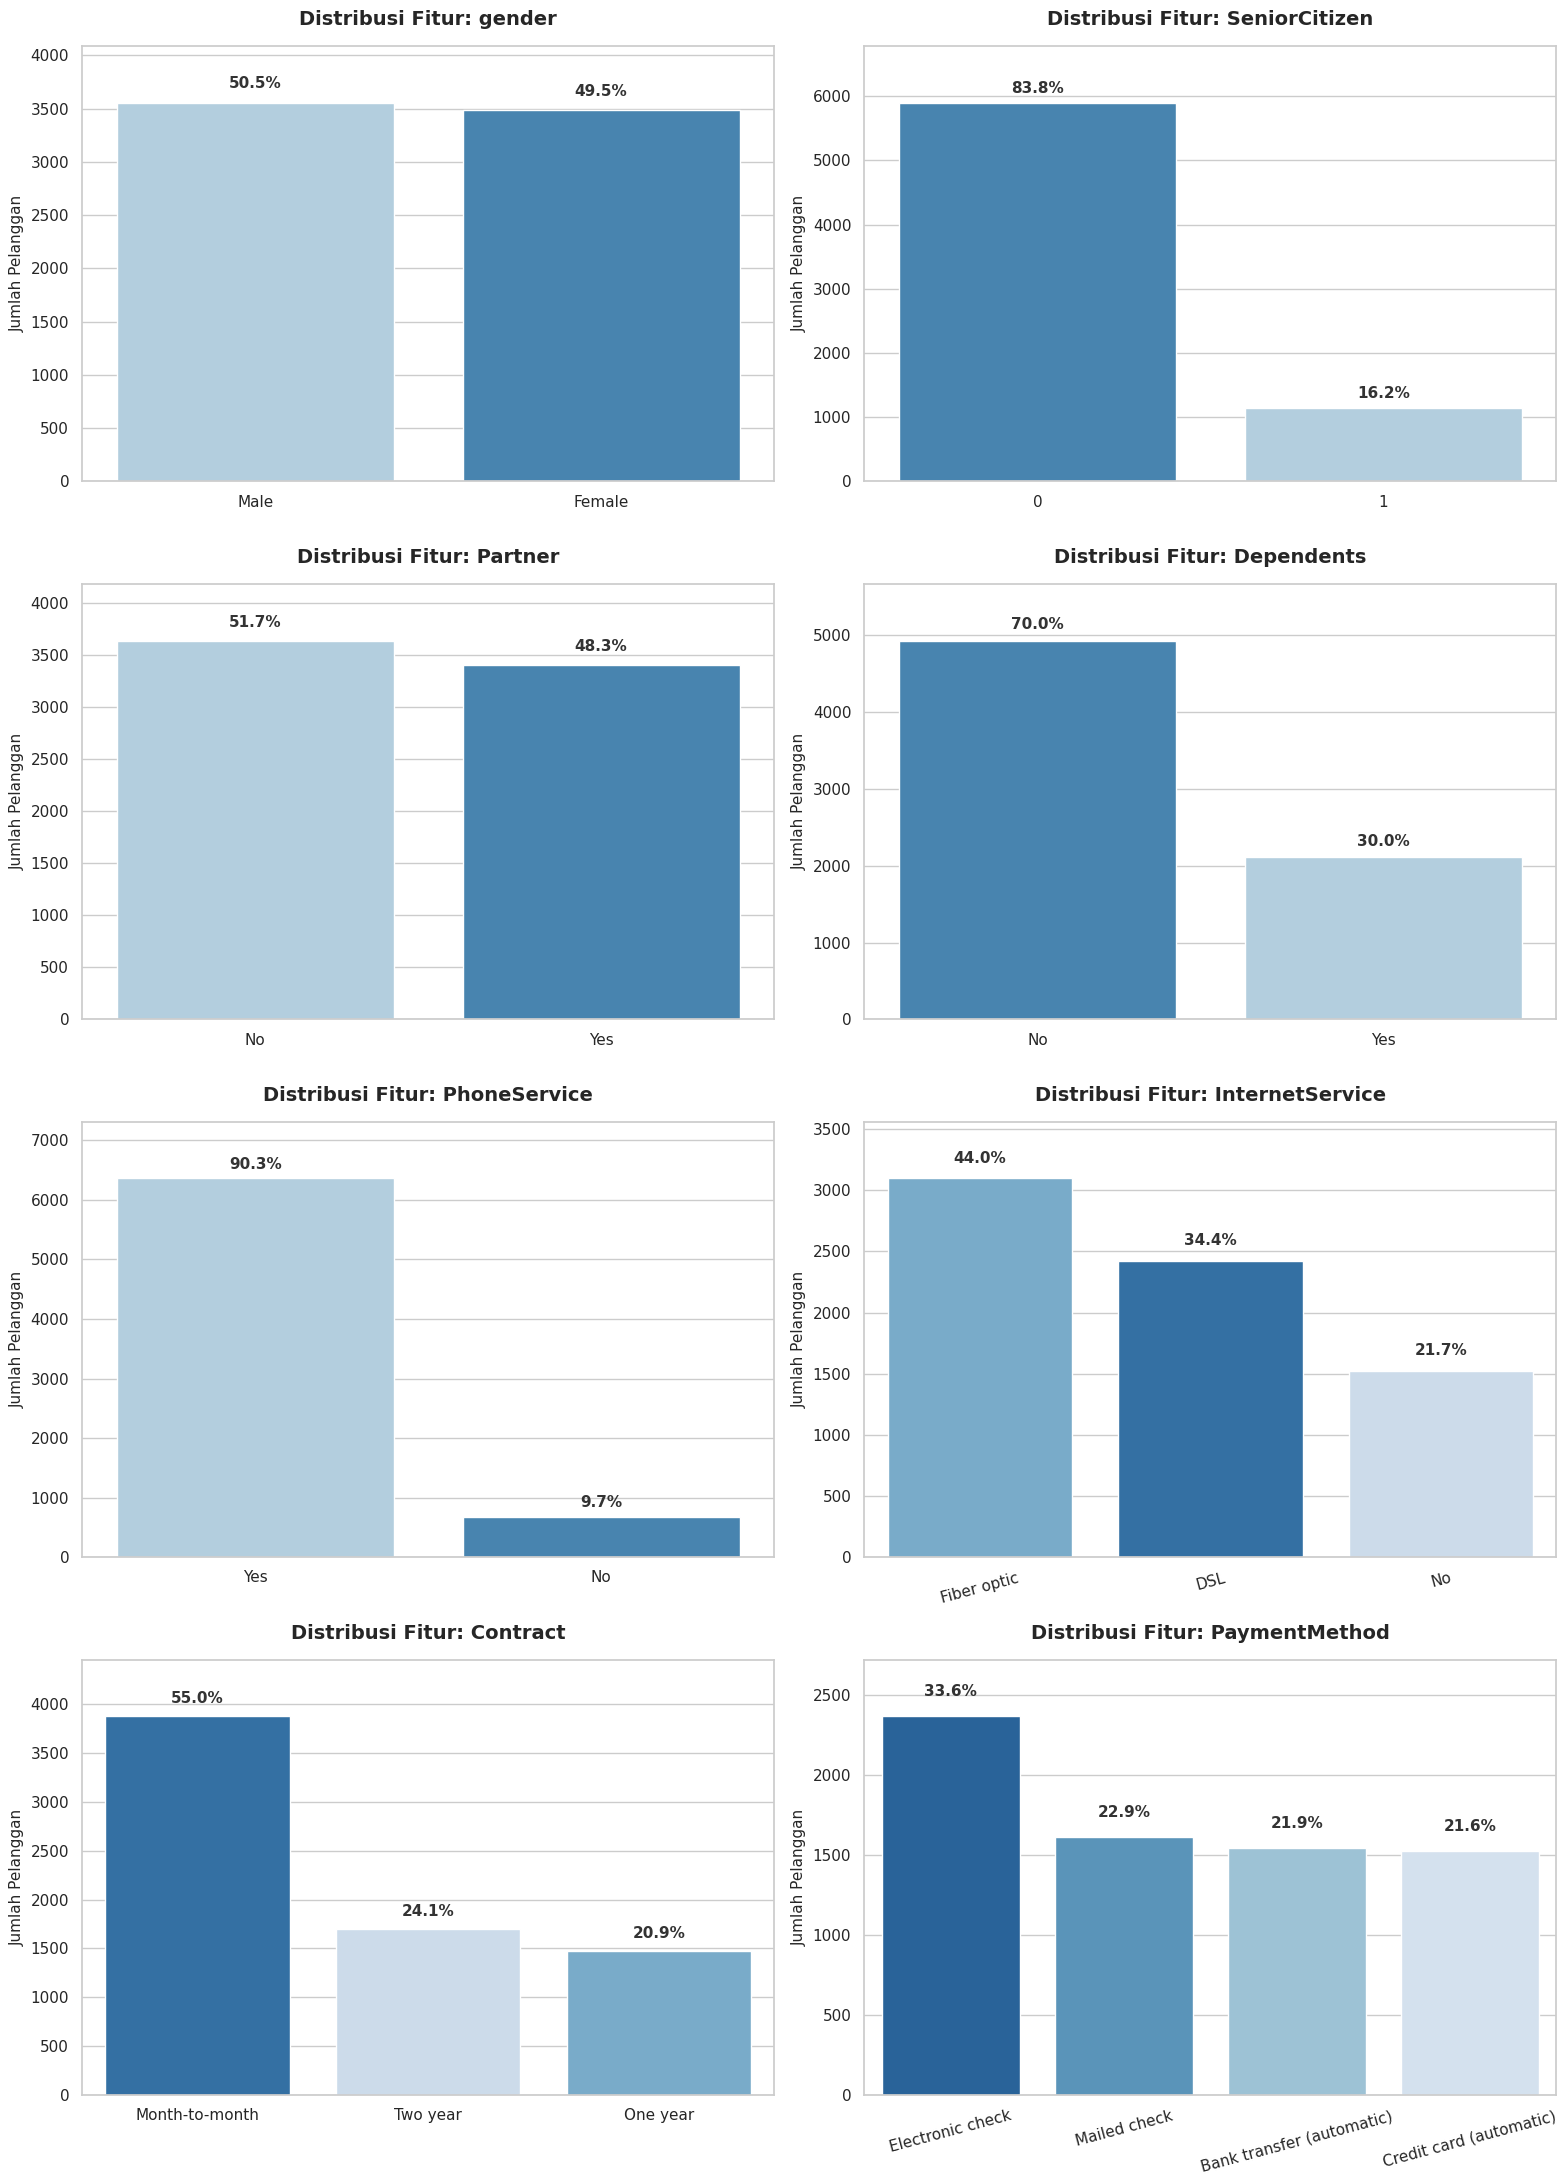

In [ ]:
# Menentukan fitur kategorikal yang penting untuk divisualisasikan
cat_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod']

# Membuat subplot dengan tata letak yang lebih rapi
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    # Membuat countplot
    ax = sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        order=df[col].value_counts().index,
        hue=col,
        palette="Blues_r",
        legend=False
    )

    # Menambahkan label persentase di atas setiap bar dengan margin yang aman
    total = len(df[col])
    for p in ax.patches:
        height = p.get_height()
        percentage = f'{100 * height / total:.1f}%'
        # Mengatur offset vertikal agar label berada tepat di atas bar
        ax.annotate(percentage,
                    (p.get_x() + p.get_width() / 2., height + (total * 0.015)),
                    ha='center', va='bottom', fontsize=11, fontweight='bold', color='#333333')

    # Merapikan judul, batas y-axis, dan label
    axes[i].set_title(f'Distribusi Fitur: {col}', fontsize=14, fontweight='bold', pad=15)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Jumlah Pelanggan', fontsize=11)
    axes[i].tick_params(axis='x', labelsize=11)

    # Memberikan ruang tambahan di atas bar agar label persentase tidak terpotong batas atas grafik
    axes[i].set_ylim(0, df[col].value_counts().max() * 1.15)

    # Memutar label sumbu X khusus untuk kolom dengan teks panjang
    if col in ['PaymentMethod', 'InternetService']:
        axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# **6. Bivariate Analysis**
## **6.1 Numerik vs numerik**
a. `Tenure` vs `MonthlyCharges`


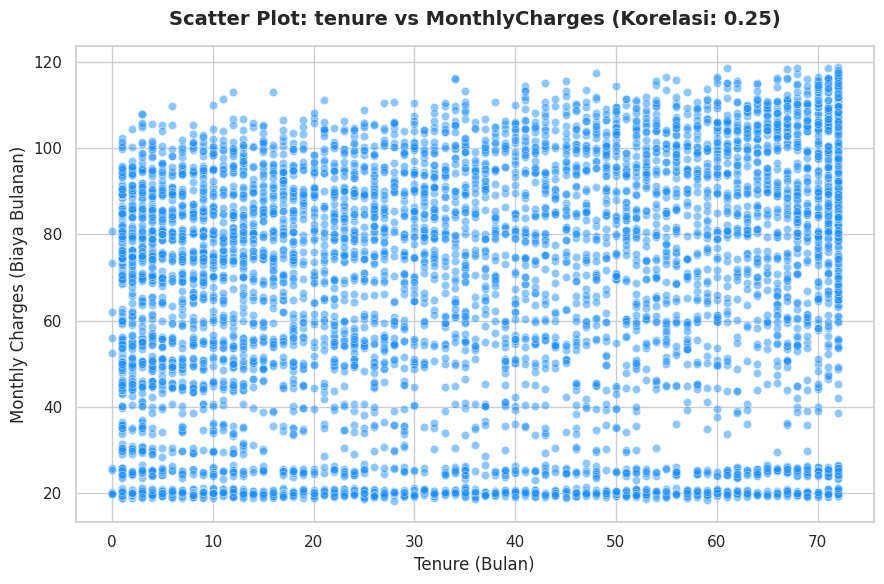

In [ ]:
# Bivariate Analysis: tenure vs MonthlyCharges menggunakan Scatter Plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='tenure',
    y='MonthlyCharges',
    alpha=0.5,
    color='dodgerblue',
    edgecolor='w',
    linewidth=0.5
)

# Menghitung korelasi Pearson
correlation = df['tenure'].corr(df['MonthlyCharges'])

plt.title(f'Scatter Plot: tenure vs MonthlyCharges (Korelasi: {correlation:.2f})', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure (Bulan)', fontsize=12)
plt.ylabel('Monthly Charges (Biaya Bulanan)', fontsize=12)
plt.tight_layout()
plt.show()

**Interpretasi:** Berdasarkan hasil analisis, diperoleh korelasi positif sebesar **0.25** antara `Tenure` dan `MonthlyCharges`. Hal ini menunjukkan adanya hubungan linear positif yang relatif lemah antara kedua variabel.

b. `Tenure` vs `TotalCharges`

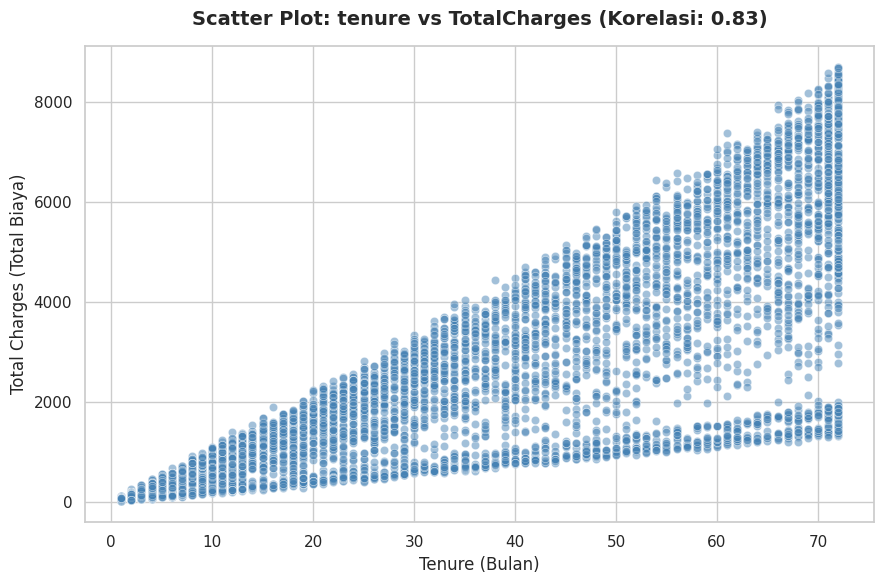

In [ ]:
# Bivariate Analysis: tenure vs TotalCharges menggunakan Scatter Plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='tenure',
    y='TotalCharges',
    alpha=0.5,
    color='steelblue',
    edgecolor='w',
    linewidth=0.5
)

# Menghitung korelasi Pearson
correlation_tc = df['tenure'].corr(df['TotalCharges'])

plt.title(f'Scatter Plot: tenure vs TotalCharges (Korelasi: {correlation_tc:.2f})', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tenure (Bulan)', fontsize=12)
plt.ylabel('Total Charges (Total Biaya)', fontsize=12)
plt.tight_layout()
plt.show()

**Interpretasi:**
Berdasarkan *scatter plot* dan nilai korelasi sebesar **0.83**, terdapat hubungan positif yang kuat antara `Tenure` dan `TotalCharges`. Hal ini menunjukkan bahwa pelanggan dengan masa berlangganan lebih lama cenderung memiliki total akumulasi biaya bulanan yang lebih tinggi.

c. `MonthlyCharges` vs `TotalCharges`

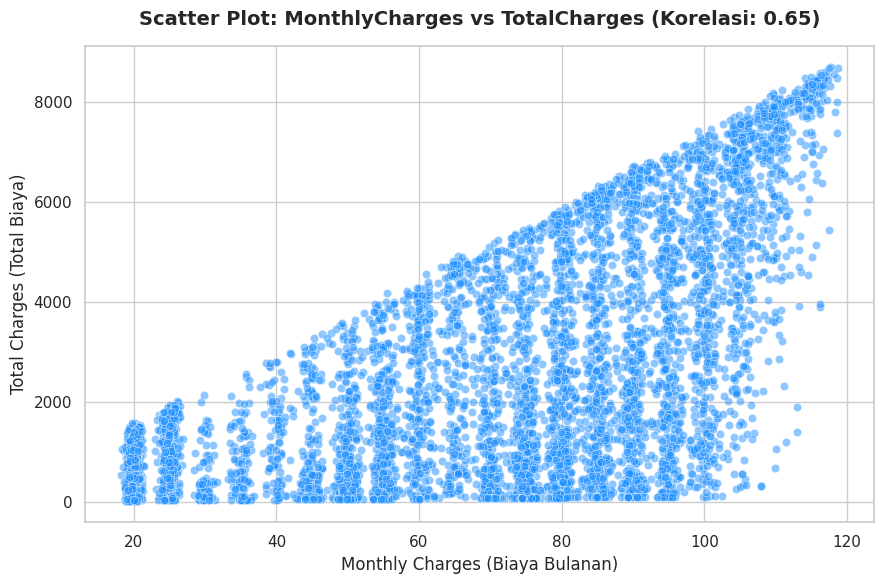

In [ ]:
# Bivariate Analysis: MonthlyCharges vs TotalCharges menggunakan Scatter Plot
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='MonthlyCharges',
    y='TotalCharges',
    alpha=0.5,
    color='dodgerblue',
    edgecolor='w',
    linewidth=0.5
)

# Menghitung korelasi Pearson
correlation_mt = df['MonthlyCharges'].corr(df['TotalCharges'])

plt.title(f'Scatter Plot: MonthlyCharges vs TotalCharges (Korelasi: {correlation_mt:.2f})', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Monthly Charges (Biaya Bulanan)', fontsize=12)
plt.ylabel('Total Charges (Total Biaya)', fontsize=12)
plt.tight_layout()
plt.show()

**Interpretasi:** Berdasarkan *scatter plot* dan nilai korelasi sebesar 0.65, terdapat hubungan positif yang cukup kuat antara `MonthlyCharges` dan `TotalCharges`. Hal ini menunjukkan bahwa pelanggan dengan biaya bulanan yang lebih tinggi cenderung memiliki kumulatif biaya bulanan yang lebih tinggi.

##**6.2 Numerik vs Kategorikal (Target)**
a. `Tenure` vs `Churn`

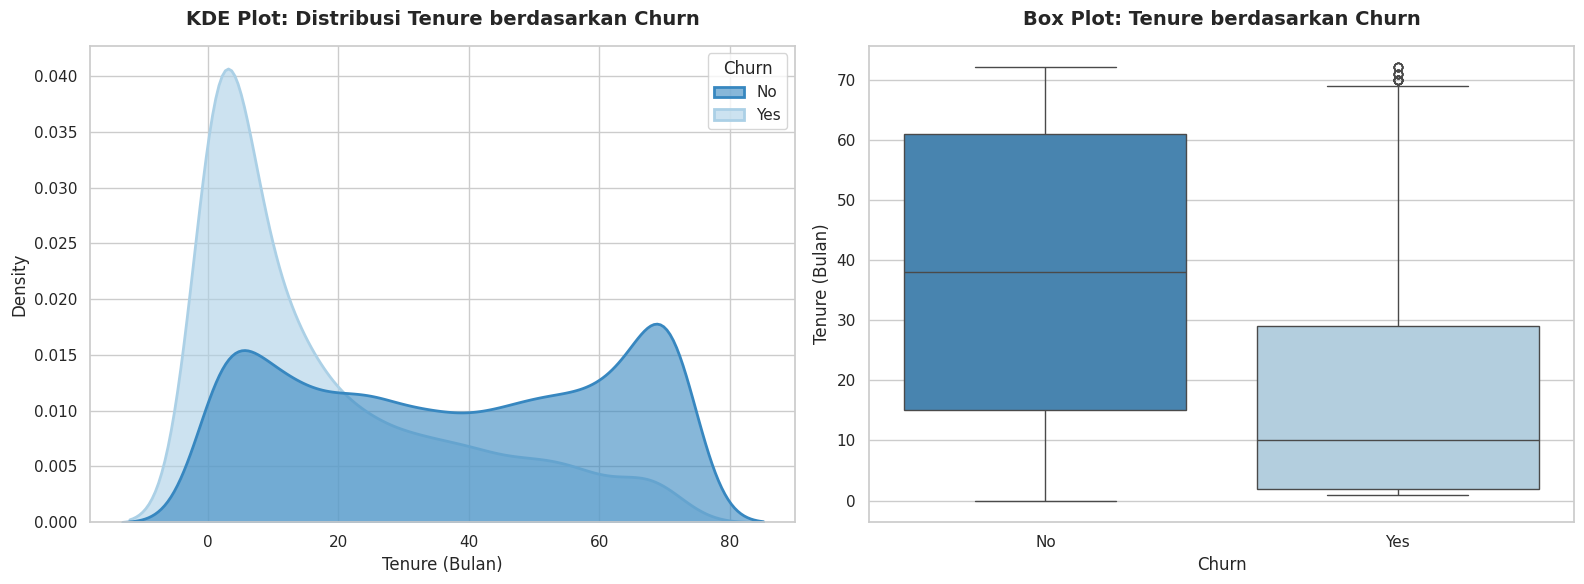

In [ ]:
# Bivariate Analysis: tenure vs Churn
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. KDE Plot untuk melihat persebaran detail
sns.kdeplot(
    data=df,
    x='tenure',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='Blues_r',
    alpha=0.6,
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title('KDE Plot: Distribusi Tenure berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Tenure (Bulan)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)

# 2. Box Plot untuk melihat median dan kuartil
sns.boxplot(
    data=df,
    x='Churn',
    y='tenure',
    palette='Blues_r',
    hue='Churn',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Box Plot: Tenure berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Churn', fontsize=12)
axes[1].set_ylabel('Tenure (Bulan)', fontsize=12)

plt.tight_layout()
plt.show()

**Interpretasi Hubungan `tenure` vs `Churn`:**
* **Risiko Tinggi di Awal**: Distribusi pelanggan yang Churn (Yes) sangat padat di area `tenure` rendah (0 - 10 bulan). Ini menunjukkan bahwa fase awal berlangganan merupakan periode paling kritis bagi pelanggan untuk memutuskan berhenti.
* **Loyalitas Jangka Panjang**: Pelanggan yang bertahan (No) memiliki sebaran yang cenderung meningkat di `tenure` tinggi (>60 bulan), menunjukkan loyalitas yang terbentuk seiring berjalannya waktu.
* **Perbedaan Median**: Secara statistik deskriptif dari Box Plot, nilai median `tenure` pelanggan yang melakukan Churn hanya **10 bulan**, sangat jauh berbeda dibandingkan pelanggan yang bertahan dengan median **38 bulan**.

b. `MonthlyCharges` vs `Churn`

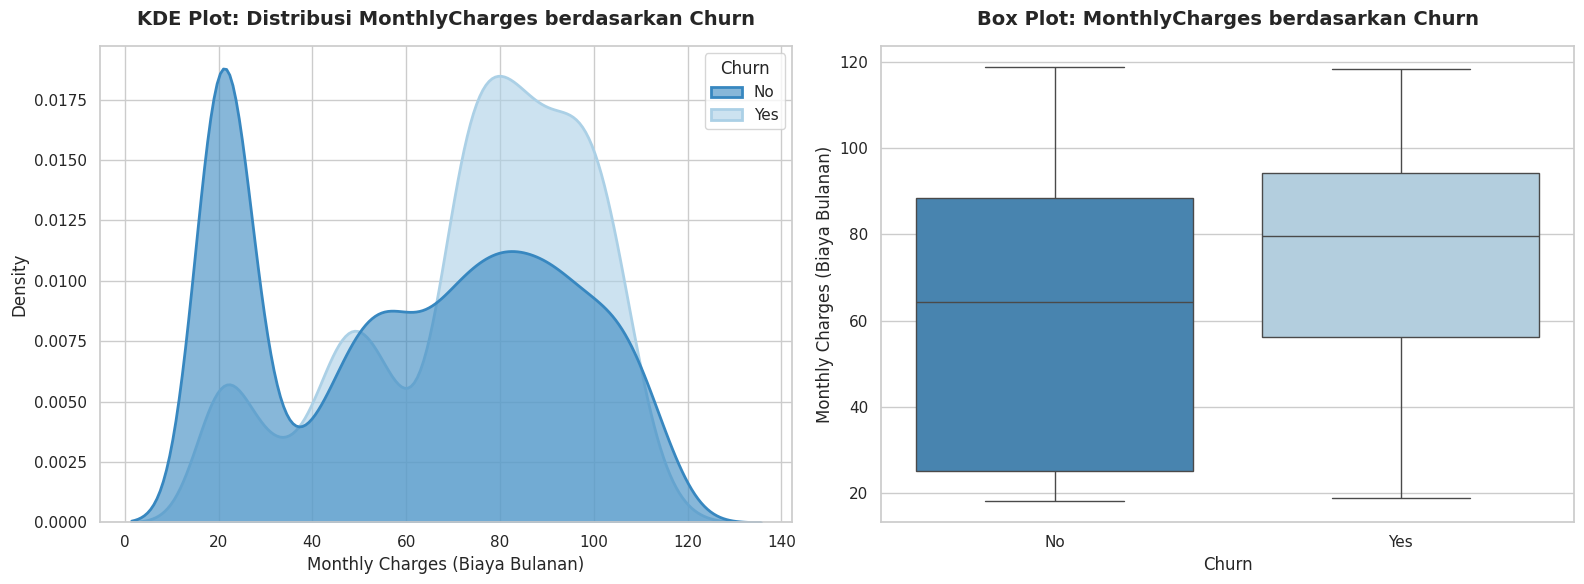

In [ ]:
# Bivariate Analysis: MonthlyCharges vs Churn
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. KDE Plot untuk melihat persebaran kepadatan (density)
sns.kdeplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='Blues_r',
    alpha=0.6,
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title('KDE Plot: Distribusi MonthlyCharges berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Monthly Charges (Biaya Bulanan)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)

# 2. Box Plot untuk melihat median, kuartil, dan rentang data
sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges',
    palette='Blues_r',
    hue='Churn',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Box Plot: MonthlyCharges berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Churn', fontsize=12)
axes[1].set_ylabel('Monthly Charges (Biaya Bulanan)', fontsize=12)

plt.tight_layout()
plt.show()

**Interpretasi Hubungan `MonthlyCharges` vs `Churn`:**
* **Biaya yang tinggi memperbesar risiko *Churn* (Yes)**: Distribusi pelanggan yang Churn (Yes) sangat padat di area `MonthlyCharges` tinggi (berkisar antara 70 - 100). Ini menunjukkan bahwa rentang biaya bulanan yang tinggi merupakan salah satu pemicu paling kritis bagi pelanggan untuk memutuskan berhenti berlangganan.
* **Pelanggan dengan Biaya Rendah Cenderung Bertahan**: Sebaliknya, pada kelompok pelanggan yang bertahan (No), terdapat puncak kepadatan yang sangat tinggi pada area biaya rendah (sekitar 20). Hal ini mengindikasikan bahwa pelanggan dengan paket layanan dasar yang murah cenderung lebih awet dan loyal.
* **Perbedaan Nilai Median**: Melalui visualisasi Box Plot, terlihat jelas bahwa nilai median biaya bulanan untuk pelanggan yang memutuskan untuk Churn jauh lebih tinggi (sekitar 80) dibandingkan dengan nilai median pelanggan yang memilih untuk tetap bertahan (sekitar 64).

c. `TotalCharges` vs `Churn`

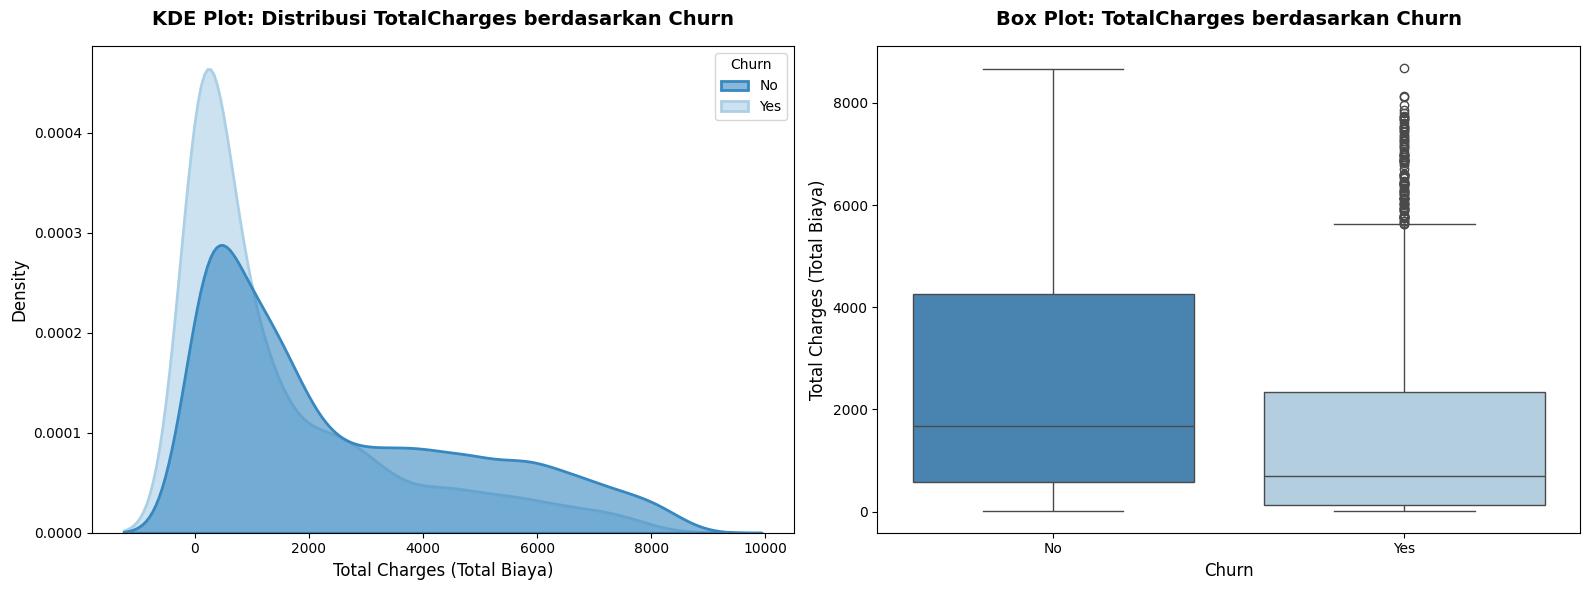

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df sudah terdefinisi, jika belum maka load ulang dari url
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Bivariate Analysis: TotalCharges vs Churn
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. KDE Plot untuk melihat persebaran kepadatan (density)
sns.kdeplot(
    data=df,
    x='TotalCharges',
    hue='Churn',
    fill=True,
    common_norm=False,
    palette='Blues_r',
    alpha=0.6,
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title('KDE Plot: Distribusi TotalCharges berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Total Charges (Total Biaya)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)

# 2. Box Plot untuk melihat median, kuartil, dan rentang data
sns.boxplot(
    data=df,
    x='Churn',
    y='TotalCharges',
    palette='Blues_r',
    hue='Churn',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Box Plot: TotalCharges berdasarkan Churn', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Churn', fontsize=12)
axes[1].set_ylabel('Total Charges (Total Biaya)', fontsize=12)

plt.tight_layout()
plt.show()

**Interpretasi Hubungan `TotalCharges` vs `Churn`:**
* **Akumulasi Biaya Rendah Mendominasi *Churn***: Distribusi pelanggan yang melakukan *Churn* (Yes) sangat terkonsentrasi pada nilai `TotalCharges` yang rendah (di bawah 2.000). Hal ini mengindikasikan bahwa sebagian besar pelanggan yang pergi adalah mereka yang baru menggunakan layanan (tenure pendek), sehingga total biaya akumulatif yang mereka bayarkan masih sedikit.
* **Pelanggan dengan Nilai Tinggi Lebih Loyal**: Distribusi pelanggan yang bertahan (No) jauh lebih landai dan menyebar hingga nilai `TotalCharges` yang sangat tinggi (mencapai lebih dari 8.000), menunjukkan kontribusi finansial jangka panjang yang stabil dari pelanggan setia.
* **Perbedaan Nilas Tengah & Outliers**: Berdasarkan Box Plot, median `TotalCharges` pelanggan yang *Churn* jauh lebih rendah dibandingkan pelanggan yang bertahan. Selain itu, terdapat beberapa titik pencilan (*outliers*) bernilai tinggi pada kelompok *Churn*, yang menandakan bahwa ada sebagian kecil pelanggan lama dengan pengeluaran kumulatif tinggi yang tetap memutuskan untuk berhenti berlangganan.

##**6.3 Kategorikal Vs Kategorikal (Target)**

a. `Dependents` vs `Churn`

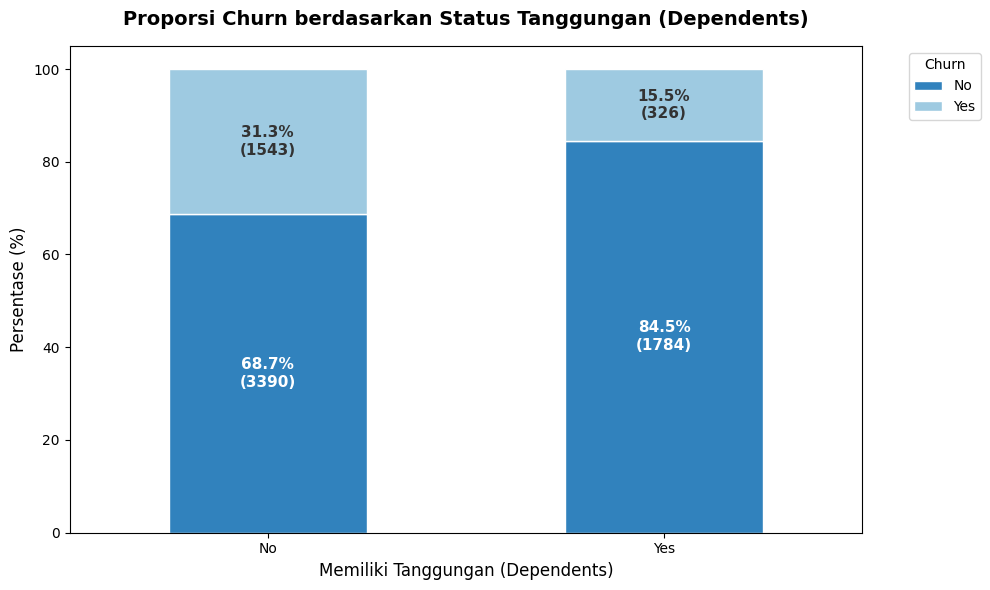

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat tabel kontingensi (crosstab) proporsi normalisasi baris
crosstab_prop = pd.crosstab(df['Dependents'], df['Churn'], normalize='index') * 100
crosstab_count = pd.crosstab(df['Dependents'], df['Churn'])

# Visualisasi: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan anotasi persentase & jumlah asli di dalam bar
for col_idx, churn_val in enumerate(crosstab_prop.columns):
    for row_idx, state in enumerate(crosstab_prop.index):
        val_pct = crosstab_prop.loc[state, churn_val]
        val_count = crosstab_count.loc[state, churn_val]
        # Tentukan posisi y (akumulasi)
        y_pos = val_pct / 2 if col_idx == 0 else crosstab_prop.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%\n({val_count})",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn berdasarkan Status Tanggungan (Dependents)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Memiliki Tanggungan (Dependents)', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretasi Hubungan `Dependents` vs `Churn`:**
* **Tingkat Churn Lebih Tinggi pada Pelanggan Tanpa Tanggungan**: Pelanggan yang tidak memiliki tanggungan keluarga (`Dependents: No`) memiliki tingkat *churn* yang jauh lebih tinggi, yaitu sebesar **31.3%** (1.543 pelanggan) dibandingkan dengan mereka yang memiliki tanggungan.
* **Pelanggan dengan Tanggungan Lebih Setia**: Pelanggan yang memiliki tanggungan keluarga (`Dependents: Yes`) menunjukkan loyalitas yang lebih tinggi dengan tingkat *churn* yang relatif rendah, yaitu hanya **15.5%** (326 pelanggan), sementara **84.5%** dari mereka memilih untuk bertahan.
* **Implikasi Bisnis**: Pelanggan dengan tanggungan keluarga cenderung memiliki profil finansial dan pola kehidupan rumah tangga yang lebih stabil, sehingga tidak mudah berganti layanan. Sebaliknya, pelanggan tanpa tanggungan lebih fleksibel dalam bermigrasi ke kompetitor dan membutuhkan perhatian ekstra melalui program retensi yang tepat.

b. `Contract` vs `Churn`

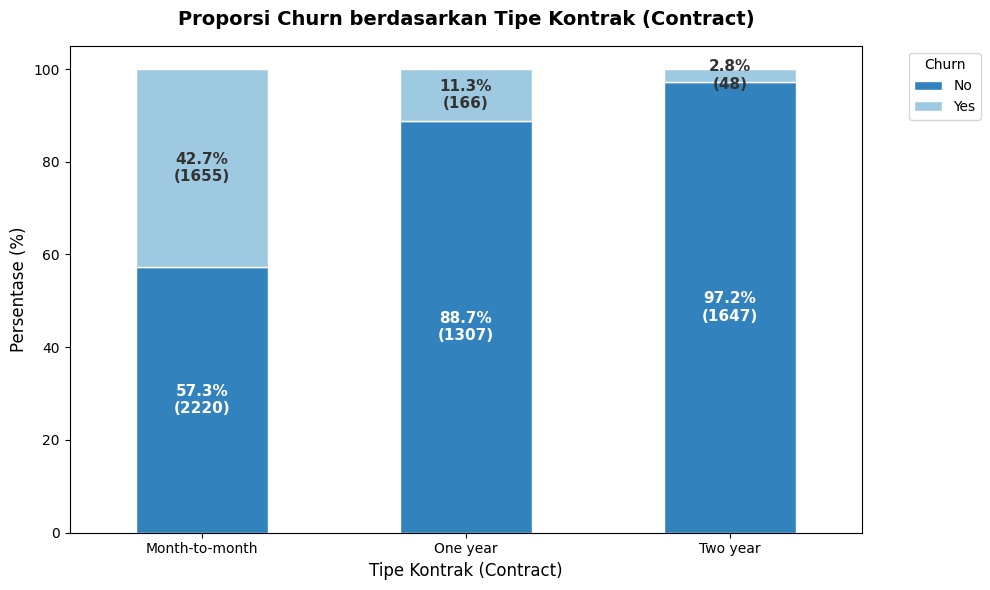

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat tabel kontingensi (crosstab) proporsi normalisasi baris
crosstab_prop = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
crosstab_count = pd.subplots
crosstab_count = pd.crosstab(df['Contract'], df['Churn'])

# Visualisasi: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan anotasi persentase & jumlah asli di dalam bar
for col_idx, churn_val in enumerate(crosstab_prop.columns):
    for row_idx, state in enumerate(crosstab_prop.index):
        val_pct = crosstab_prop.loc[state, churn_val]
        val_count = crosstab_count.loc[state, churn_val]
        # Tentukan posisi y (akumulasi)
        y_pos = val_pct / 2 if col_idx == 0 else crosstab_prop.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%\n({val_count})",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn berdasarkan Tipe Kontrak (Contract)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tipe Kontrak (Contract)', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretasi Hubungan `Dependents` vs `Churn`:**

* **Tingkat Churn Lebih Tinggi pada Pelanggan Kontrak Month-to-month**: Pelanggan yang berkontrak Month-to-Month memiliki tingkat *churn* yang jauh lebih tinggi, yaitu sebesar **42.7%** (1655 pelanggan) dibandingkan dengan mereka yang memiliki kontrak satu atau dua tahun.
*  **Pelanggan dengan kontrak 1 dan 2 tahun (`Contract: One Year & Two Year`) lebih setia**: Pelanggan yang menjalin kontrak selama 1 dan 2 tahun menunjukkan kepercayaan yang sangat tinggi pada produk perusahaan dengan tingkat *churn* yang sangat rendah, yakni masing-masing hanya **11.3%** (166 pelanggan) dan **2.8%** (48 pelanggan), sementara masing-masing dari keduanya terdapat **88.7%** dan **97.2%** dari mereka memilih untuk bertahan.
* **Implikasi Bisnis**: Pelanggan dengan kontrak 1 atau 2 tahun (`contract: One year & Two years`) cenderung memiliki kepercayaan yang tinggi terhadap produk dan layanan yang tersedia pada perusahaan, sehingga tidak mudah berganti layanan. Sebaliknya, pelanggan (`contract: Month-to-Month`)  lebih fleksibel dalam bermigrasi ke kompetitor dan membutuhkan perhatian ekstra melalui program retensi yang tepat.


c. `InternetService` vs `Churn`

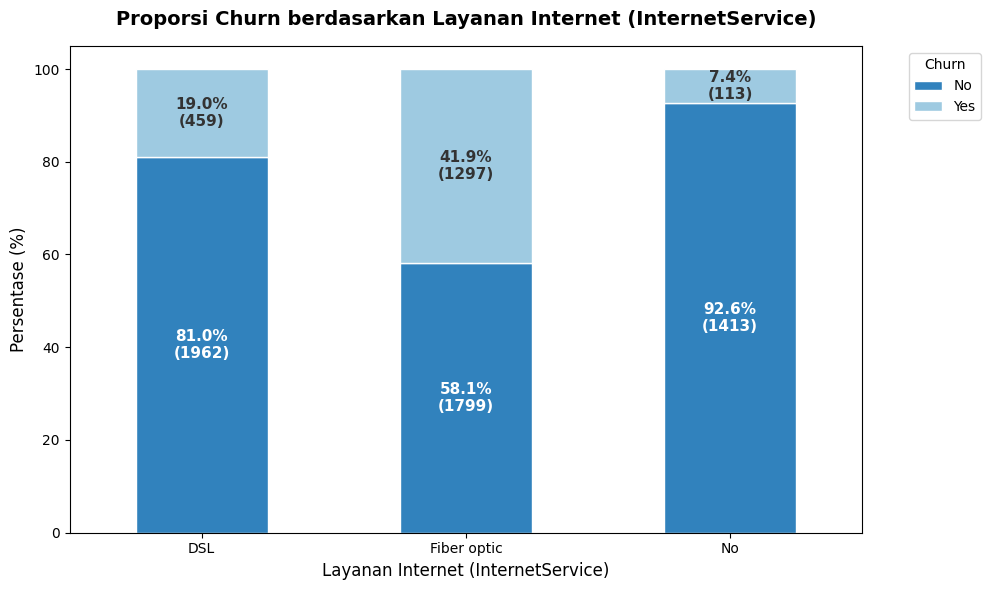

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat tabel kontingensi (crosstab) proporsi normalisasi baris
crosstab_prop = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100
crosstab_count = pd.crosstab(df['InternetService'], df['Churn'])

# Visualisasi: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan anotasi persentase & jumlah asli di dalam bar
for col_idx, churn_val in enumerate(crosstab_prop.columns):
    for row_idx, state in enumerate(crosstab_prop.index):
        val_pct = crosstab_prop.loc[state, churn_val]
        val_count = crosstab_count.loc[state, churn_val]
        # Tentukan posisi y (akumulasi)
        y_pos = val_pct / 2 if col_idx == 0 else crosstab_prop.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%\n({val_count})",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn berdasarkan Layanan Internet (InternetService)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Layanan Internet (InternetService)', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretasi Hubungan `InternetService` vs `Churn`:**

* **Tingkat Churn Sangat Tinggi pada Pelanggan Fiber Optic**: Pelanggan yang menggunakan layanan internet **Fiber optic** memiliki tingkat *churn* yang sangat tinggi, yaitu sebesar **41.8%** (1.297 pelanggan), jauh lebih tinggi dibandingkan pengguna DSL maupun yang tidak memiliki layanan internet.
* **Pelanggan DSL dan Tanpa Layanan Internet Lebih Stabil**: Pelanggan dengan layanan **DSL** memiliki tingkat *churn* sedang sebesar **19.0%** (459 pelanggan), sedangkan pelanggan yang tidak menggunakan layanan internet (`No`) memiliki tingkat *churn* paling rendah, yaitu hanya **7.4%** (113 pelanggan).
* **Implikasi Bisnis**: Layanan *Fiber optic* yang umumnya lebih mahal dan cepat ternyata memiliki masalah retensi yang signifikan. Hal ini perlu diselidiki lebih lanjut (apakah karena masalah stabilitas koneksi, ekspektasi harga, atau kurangnya dukungan teknis) guna menekan angka kehilangan pelanggan pada segmen premium tersebut.

d. `Phoneservice` vs `Churn`

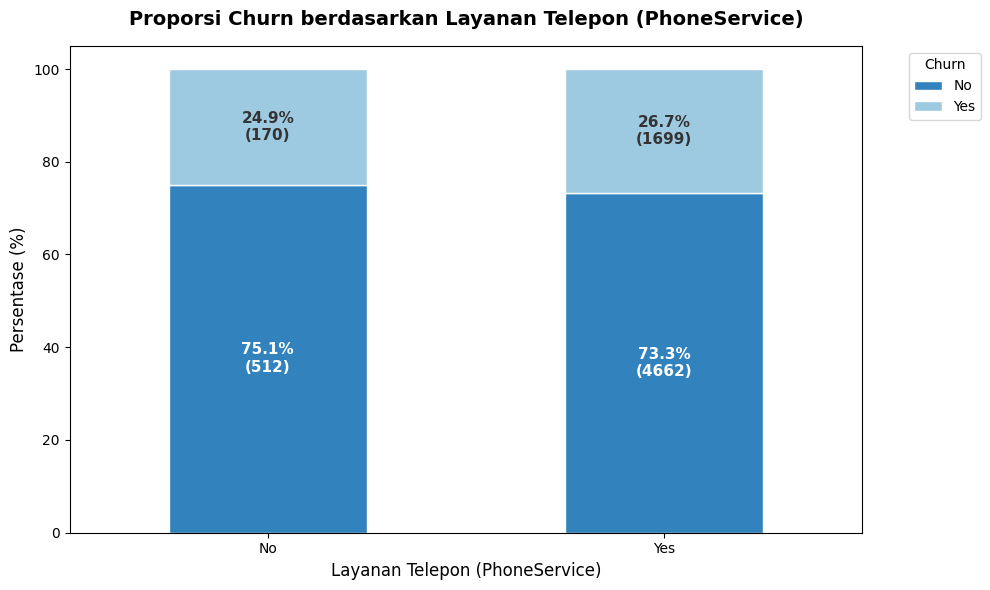

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat tabel kontingensi (crosstab) proporsi normalisasi baris
crosstab_prop = pd.crosstab(df['PhoneService'], df['Churn'], normalize='index') * 100
crosstab_count = pd.crosstab(df['PhoneService'], df['Churn'])

# Visualisasi: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan anotasi persentase & jumlah asli di dalam bar
for col_idx, churn_val in enumerate(crosstab_prop.columns):
    for row_idx, state in enumerate(crosstab_prop.index):
        val_pct = crosstab_prop.loc[state, churn_val]
        val_count = crosstab_count.loc[state, churn_val]
        # Tentukan posisi y (akumulasi)
        y_pos = val_pct / 2 if col_idx == 0 else crosstab_prop.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%\n({val_count})",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn berdasarkan Layanan Telepon (PhoneService)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Layanan Telepon (PhoneService)', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretasi Hubungan `PhoneService` vs `Churn`:**

* **Tingkat Churn Serupa pada Kedua Kelompok**: Pelanggan yang memiliki layanan telepon (`Yes`) memiliki tingkat *churn* sebesar **26.7%** (1.699 pelanggan). Angka ini sangat mirip dengan pelanggan yang tidak memiliki layanan telepon (`No`) yang memiliki tingkat *churn* sebesar **24.9%** (170 pelanggan).
* **Indikasi Hubungan**: Karena perbedaan persentase *churn* antara pengguna layanan telepon dan non-pengguna sangat tipis (~1.8%), fitur `PhoneService` secara mandiri tampaknya tidak memiliki pengaruh yang signifikan dalam membedakan apakah pelanggan akan *churn* atau bertahan.

e. `Partner` vs `Churn`

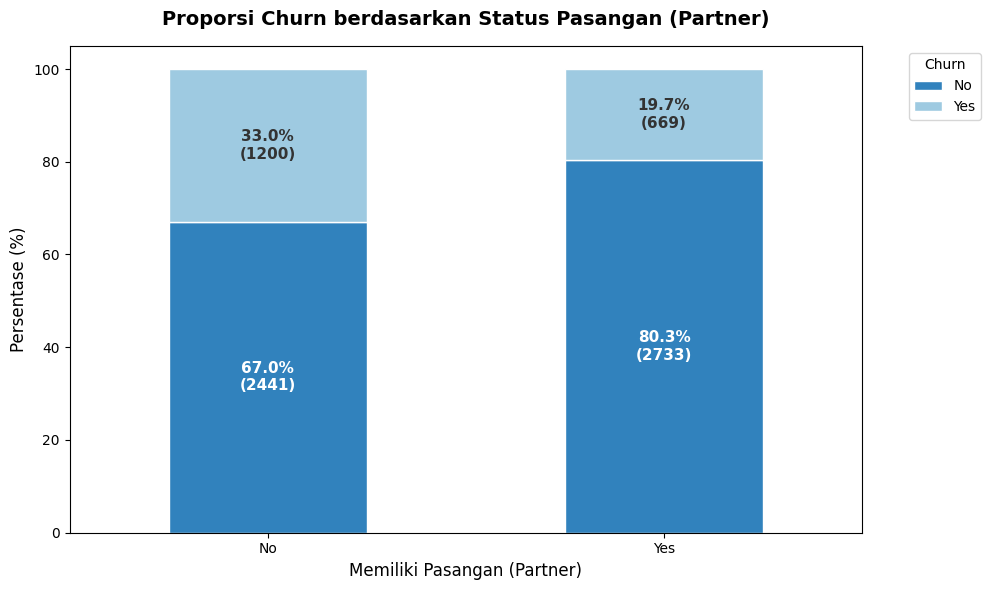

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat tabel kontingensi (crosstab) proporsi normalisasi baris
crosstab_prop = pd.crosstab(df['Partner'], df['Churn'], normalize='index') * 100
crosstab_count = pd.crosstab(df['Partner'], df['Churn'])

# Visualisasi: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))

crosstab_prop.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan anotasi persentase & jumlah asli di dalam bar
for col_idx, churn_val in enumerate(crosstab_prop.columns):
    for row_idx, state in enumerate(crosstab_prop.index):
        val_pct = crosstab_prop.loc[state, churn_val]
        val_count = crosstab_count.loc[state, churn_val]
        # Tentukan posisi y (akumulasi)
        y_pos = val_pct / 2 if col_idx == 0 else crosstab_prop.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%\n({val_count})",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn berdasarkan Status Pasangan (Partner)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Memiliki Pasangan (Partner)', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretasi Hubungan `Partner` vs `Churn`:**

* **Tingkat Churn Lebih Tinggi pada Pelanggan Tanpa Pasangan**: Pelanggan yang tidak memiliki pasangan (`Partner: No`) menunjukkan tingkat *churn* yang lebih tinggi, yaitu sebesar **33.0%** (1.200 pelanggan) dibandingkan dengan mereka yang memiliki pasangan.
* **Pelanggan dengan Pasangan Lebih Setia**: Pelanggan yang memiliki pasangan (`Partner: Yes`) cenderung lebih loyal dengan tingkat *churn* yang lebih rendah, yaitu hanya **19.7%** (669 pelanggan), dengan **80.3%** di antaranya memilih bertahan.
* **Implikasi Bisnis**: Adanya pasangan hidup tampaknya berkorelasi dengan kestabilan tinggal di suatu tempat atau kestabilan pengeluaran rumah tangga yang membuat mereka cenderung tetap menggunakan layanan telekomunikasi yang sama secara jangka panjang.

# **7. Corelation Heatmap & Multivariate Analysis**
## **7.1 Numerik Corelation Heatmap**



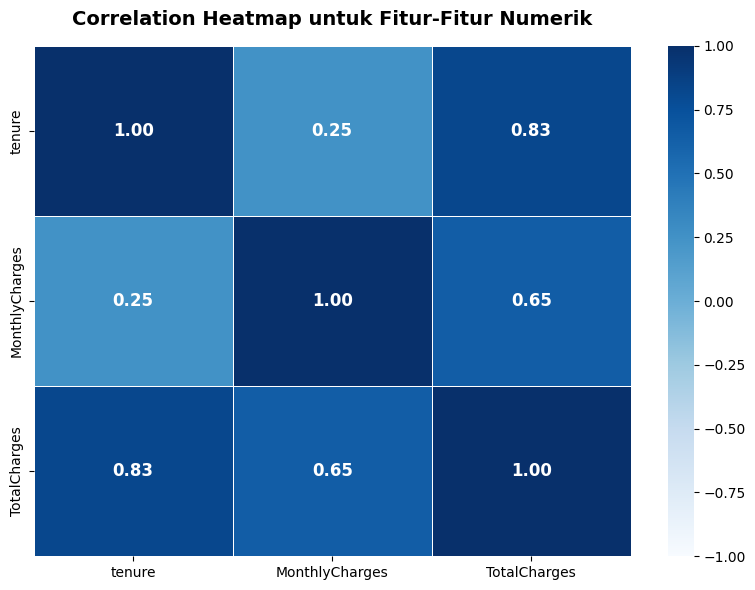

In [ ]:
# Menghitung korelasi antar fitur numerik
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
corr_matrix = df[numeric_cols].corr()

# Membuat visualisasi Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5,
    annot_kws={'size': 12, 'weight': 'bold'},
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap untuk Fitur-Fitur Numerik', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

**Interpretasi Hasil Correlation Heatmap:**

* **Korelasi Sangat Kuat antara `tenure` dan `TotalCharges` (0.83)**: Hubungan positif yang sangat kuat ini sangat logis karena akumulasi total biaya (`TotalCharges`) berbanding lurus dengan lamanya waktu pelanggan berlangganan (`tenure`).
* **Korelasi Kuat antara `MonthlyCharges` dan `TotalCharges` (0.65)**: Pelanggan dengan biaya bulanan (`MonthlyCharges`) yang tinggi secara otomatis akan menghasilkan akumulasi biaya keseluruhan (`TotalCharges`) yang besar pula seiring waktu.
* **Korelasi Lemah antara `tenure` dan `MonthlyCharges` (0.25)**: Hubungan yang relatif rendah ini mengindikasikan bahwa lamanya masa berlangganan seorang pelanggan tidak secara signifikan memengaruhi besaran biaya paket bulanan yang mereka pilih (atau sebaliknya).
## **7.2 Kategorikal Corelation Heatmap**

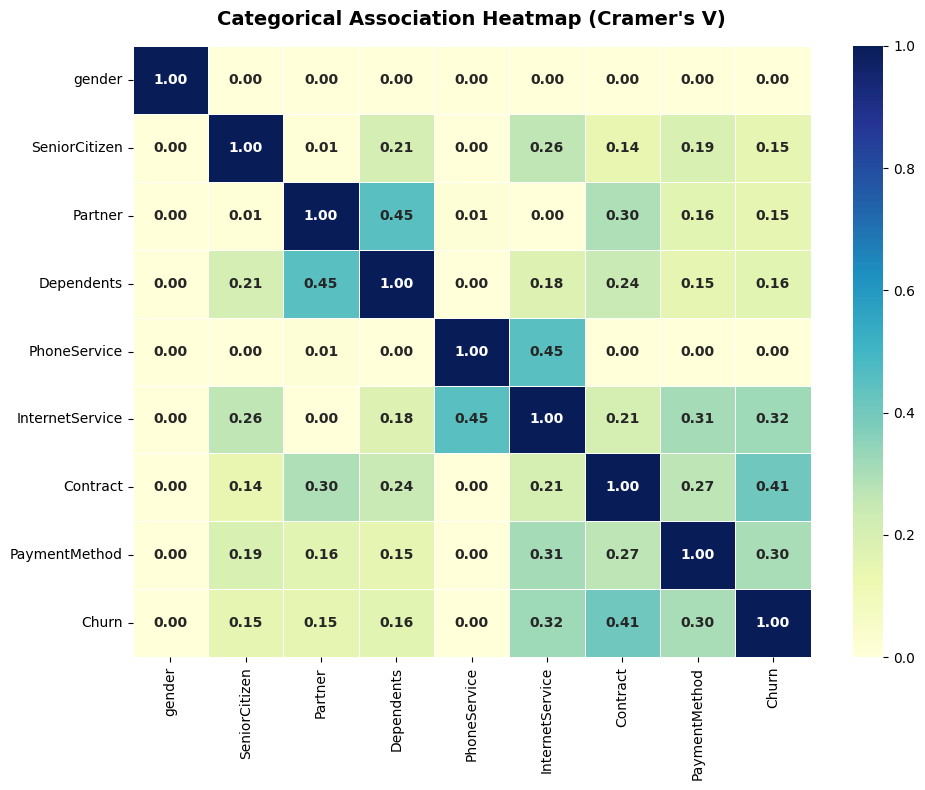

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Fungsi untuk menghitung Cramer's V antara dua kolom kategorikal
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Daftar fitur kategorikal penting ditambah target Churn
cat_features_heatmap = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'InternetService', 'Contract', 'PaymentMethod', 'Churn']

# Mempersiapkan matriks Cramer's V
n_features = len(cat_features_heatmap)
cramers_matrix = pd.DataFrame(np.zeros((n_features, n_features)), columns=cat_features_heatmap, index=cat_features_heatmap)

# Menghitung Cramer's V untuk setiap pasangan
for col1 in cat_features_heatmap:
    for col2 in cat_features_heatmap:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0
        else:
            # Mengabaikan missing values secara berpasangan jika ada
            clean_pair = df[[col1, col2]].dropna()
            cramers_matrix.loc[col1, col2] = cramers_v(clean_pair[col1], clean_pair[col2])

# Visualisasi Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cramers_matrix,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f',
    linewidths=0.5,
    annot_kws={'size': 10, 'weight': 'bold'},
    vmin=0,
    vmax=1
)

plt.title("Categorical Association Heatmap (Cramer's V)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### **Interpretasi Hasil Categorical Correlation Heatmap (Cramer's V)**

Analisis korelasi variabel kategorikal menggunakan metode **Cramer's V** memberikan pemahaman tentang kekuatan asosiasi (dari skala `0` hingga `1`) antara fitur-fitur kategorikal dengan target variabel (`Churn`) maupun antar sesama fitur independen:

#### **1. Fitur Utama yang Berasosiasi Kuat dengan Churn**
* **`Contract` (0.41)**: Memiliki nilai asosiasi tertinggi dengan `Churn`. Hal ini menunjukkan bahwa struktur atau jenis kontrak berlangganan (seperti *Month-to-month* vs *Two-year*) merupakan faktor penentu paling dominan dalam menentukan apakah pelanggan akan pergi atau bertahan.
* **`InternetService` (0.32)**: Jenis teknologi internet yang digunakan pelanggan memiliki asosiasi moderat yang signifikan dengan keputusan churn. Ini sejalan dengan analisis bivariat sebelumnya di mana pengguna layanan premium (Fiber Optic) menunjukkan angka churn yang sangat tinggi.
* **`PaymentMethod` (0.30)**: Metode pembayaran juga memiliki pengaruh moderat yang cukup kuat terhadap churn, kemungkinan berkaitan dengan kenyamanan transaksi atau kegagalan pembayaran otomatis.

#### **2. Hubungan Antar Fitur Independen (Indikasi Multikolinearitas)**
* **`Partner` vs `Dependents` (0.45)**: Terdapat asosiasi moderat yang kuat antara status memiliki pasangan hidup dan kepemilikan tanggungan finansial. Ini sangat wajar secara demografis karena seseorang yang sudah menikah cenderung memiliki tanggungan (anak/orang tua).
* **`PhoneService` vs `InternetService` (0.45)**: Pelanggan yang memiliki layanan telepon juga sering kali memiliki atau memilih jenis paket layanan internet tertentu secara bersamaan (*bundling*).

#### **3. Fitur dengan Hubungan Sangat Lemah / Tidak Berpengaruh**
* **`gender` (0.00)**: Memiliki nilai asosiasi mutlak nol (`0.00`) terhadap variabel `Churn` maupun seluruh fitur lainnya. Ini menunjukkan bahwa **faktor gender sama sekali tidak berpengaruh** terhadap kecenderungan pelanggan untuk berhenti atau melanjutkan langganan.

## **7.3 Multivariate Analysis**
a. `Tenure` vs `Dependents` vs `Churn`

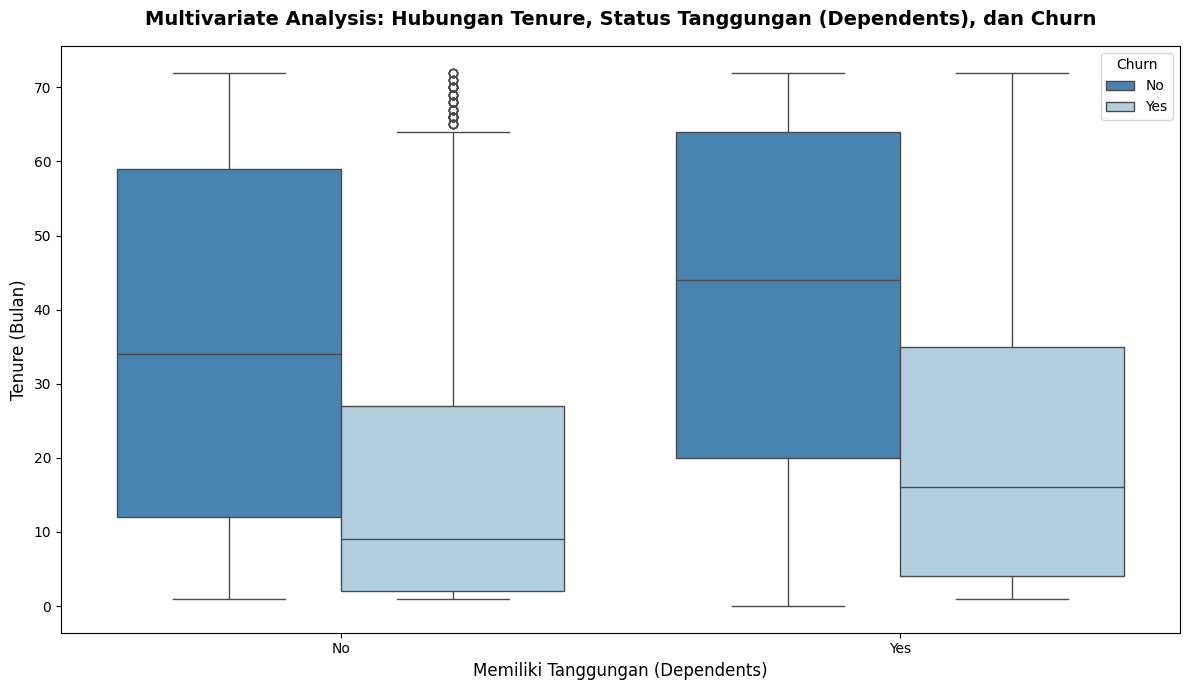

count  mean  median   std
Dependents Churn                           
No         No      3390  35.6    34.0  24.2
           Yes     1543  17.1     9.0  19.1
Yes        No      1784  41.4    44.0  23.5
           Yes      326  22.0    16.0  21.2

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat visualisasi Multivariate: Tenure vs Dependents vs Churn
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='Dependents',
    y='tenure',
    hue='Churn',
    palette='Blues_r'
)

plt.title("Multivariate Analysis: Hubungan Tenure, Status Tanggungan (Dependents), dan Churn", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Memiliki Tanggungan (Dependents)", fontsize=12)
plt.ylabel("Tenure (Bulan)", fontsize=12)
plt.legend(title="Churn", loc='upper right')
plt.tight_layout()
plt.show()

# Menghitung ringkasan statistik untuk mendukung visualisasi
summary_stats = df.groupby(['Dependents', 'Churn'])['tenure'].agg(['count', 'mean', 'median', 'std']).round(1)
display(summary_stats)

### **Interpretasi Hasil Multivariate Analysis: `tenure` vs `Dependents` vs `Churn`**

Melalui analisis gabungan ini, kita dapat menarik beberapa poin kesimpulan penting mengenai interaksi antara masa berlangganan, status keluarga (tanggungan), dan keputusan untuk berhenti berlangganan (*churn*):

1. **Kerentanan di Bulan-Bulan Awal Terjadi pada Semua Kelompok**:
   * Baik pelanggan yang memiliki tanggungan (`Dependents: Yes`) maupun yang tidak (`No`), apabila mereka memutuskan untuk *churn* (Yes), hal tersebut mayoritas terjadi pada masa **tenure yang sangat singkat**.
   * Median *tenure* kelompok *churn* pada pelanggan tanpa tanggungan adalah **9 bulan**, sedangkan bagi pelanggan yang memiliki tanggungan sedikit lebih lama yaitu **16 bulan**.

2. **Efek Stabilisasi dari Kepemilikan Tanggungan**:
   * Pelanggan dengan status `Dependents: Yes` yang memilih bertahan (`Churn: No`) memiliki median *tenure* tertinggi, yaitu mencapai **44 bulan**.
   * Ini menegaskan kembali bahwa kombinasi profil demografis yang stabil (memiliki keluarga/tanggungan) dipadukan dengan melewati masa kritis awal tahun pertama membuat kelompok ini menjadi segmen pelanggan yang paling loyal dan bernilai tinggi bagi perusahaan.

b. `Dependents` vs `Partner` vs `Churn`

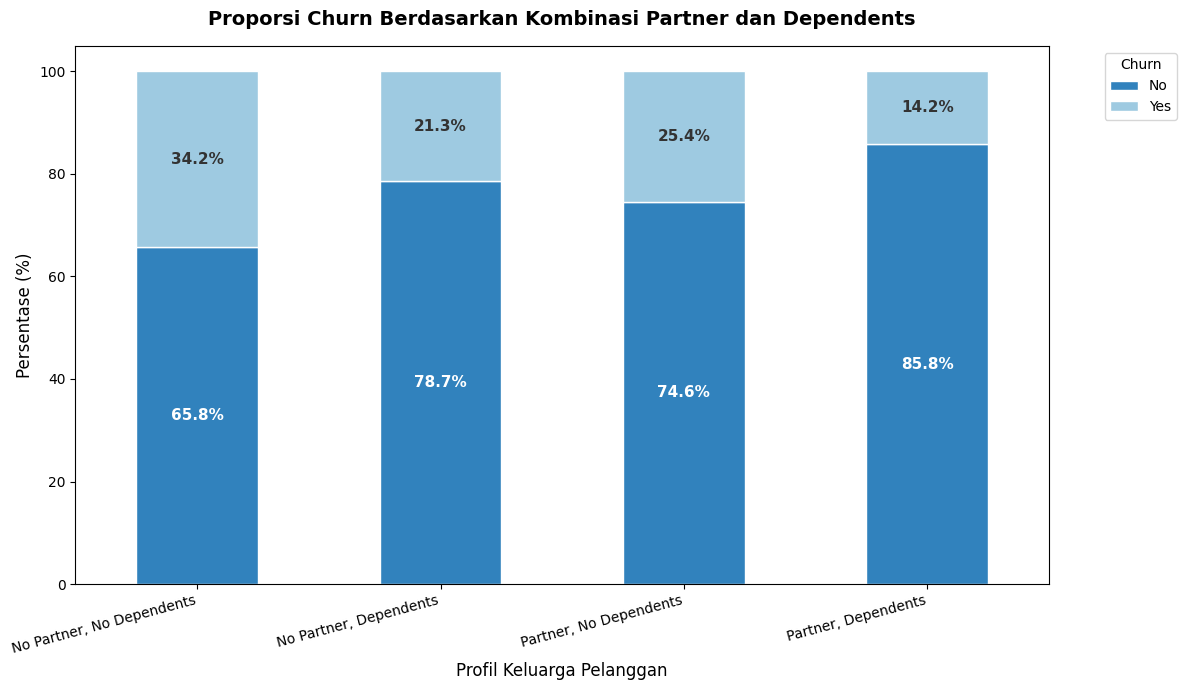

Churn,No,Yes
Family_Profile,,
"No Partner, Dependents",284,77
"No Partner, No Dependents",2157,1123
"Partner, Dependents",1500,249
"Partner, No Dependents",1233,420


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Membuat kolom kombinasi profil keluarga
df['Family_Profile'] = 'No Partner, No Dependents'
df.loc[(df['Partner'] == 'Yes') & (df['Dependents'] == 'No'), 'Family_Profile'] = 'Partner, No Dependents'
df.loc[(df['Partner'] == 'No') & (df['Dependents'] == 'Yes'), 'Family_Profile'] = 'No Partner, Dependents'
df.loc[(df['Partner'] == 'Yes') & (df['Dependents'] == 'Yes'), 'Family_Profile'] = 'Partner, Dependents'

# Membuat tabel kontingensi untuk proporsi Churn
profile_churn = pd.crosstab(df['Family_Profile'], df['Churn'], normalize='index') * 100
profile_churn = profile_churn.reindex([
    'No Partner, No Dependents',
    'No Partner, Dependents',
    'Partner, No Dependents',
    'Partner, Dependents'
])

# Visualisasi: Grouped Stacked Bar Chart
fig, ax = plt.subplots(figsize=(12, 7))
profile_churn.plot(
    kind='bar',
    stacked=True,
    color=['#3182bd', '#9ecae1'],
    edgecolor='white',
    ax=ax
)

# Menambahkan label persentase
for col_idx, churn_val in enumerate(profile_churn.columns):
    for row_idx, profile in enumerate(profile_churn.index):
        val_pct = profile_churn.loc[profile, churn_val]
        y_pos = val_pct / 2 if col_idx == 0 else profile_churn.iloc[row_idx, 0] + (val_pct / 2)
        ax.text(
            row_idx,
            y_pos,
            f"{val_pct:.1f}%",
            ha='center',
            va='center',
            color='white' if col_idx == 0 else '#333333',
            fontweight='bold',
            fontsize=11
        )

plt.title('Proporsi Churn Berdasarkan Kombinasi Partner dan Dependents', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Profil Keluarga Pelanggan', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Menghitung jumlah kasus riil
display(pd.crosstab(df['Family_Profile'], df['Churn']))

### **Interpretasi Hasil Multivariate Analysis: `Partner` vs `Dependents` vs `Churn`**

Analisis gabungan antara status pernikahan/pasangan (`Partner`) dan tanggung jawab finansial (`Dependents`) terhadap keputusan berhenti berlangganan (*churn*) menunjukkan pola sosio-demografis yang sangat jelas:

1. **Kelompok Paling Rentan Churn (Single & Mandiri - *No Partner, No Dependents*)**:
   * Pelanggan yang **tidak memiliki pasangan sekaligus tidak memiliki tanggungan** memiliki tingkat *churn* tertinggi, yaitu mencapai **34.2%** (1.123 pelanggan).
   * Kelompok ini tidak memiliki ikatan rumah tangga yang kompleks, membuat mereka sangat fleksibel secara finansial untuk berpindah ke kompetitor kapan saja jika menemukan penawaran yang lebih menarik.

2. **Kombinasi Transisi (Memiliki Salah Satu - *Partner* saja atau *Dependents* saja)**:
   * Pelanggan dengan **Partner tetapi No Dependents** memiliki tingkat *churn* sebesar **25.4%**.
   * Pelanggan tanpa Partner tetapi memiliki **Dependents** memiliki tingkat *churn* sebesar **21.3%**.
   * Keberadaan salah satu faktor (pasangan atau anak/keluarga) mulai memberikan efek stabilitas terhadap perilaku berlangganan mereka.

3. **Kelompok Paling Loyal (Keluarga Utuh - *Partner, Dependents*)**:
   * Pelanggan yang **memiliki pasangan sekaligus memiliki tanggungan** menunjukkan tingkat loyalitas tertinggi dengan persentase *churn* terendah, yaitu hanya **14.2%** (249 pelanggan), sedangkan **85.8%** di antaranya memilih bertahan.
   * Profil keluarga yang mapan dan menetap ini cenderung menghindari kerumitan mengganti penyedia layanan internet rumah/telepon karena layanan tersebut umumnya digunakan bersama oleh seluruh anggota keluarga.

**Kesimpulan Strategis**: Tim retensi pemasaran sebaiknya memprioritaskan program promosi atau insentif kontrak jangka panjang kepada segmen pelanggan mandiri (*No Partner, No Dependents*) yang merupakan kelompok penyumbang angka kehilangan pelanggan terbesar.

c. `Partner` vs `Dependents` vs `Contract` vs `Churn`

/tmp/ipykernel_768/4195736175.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


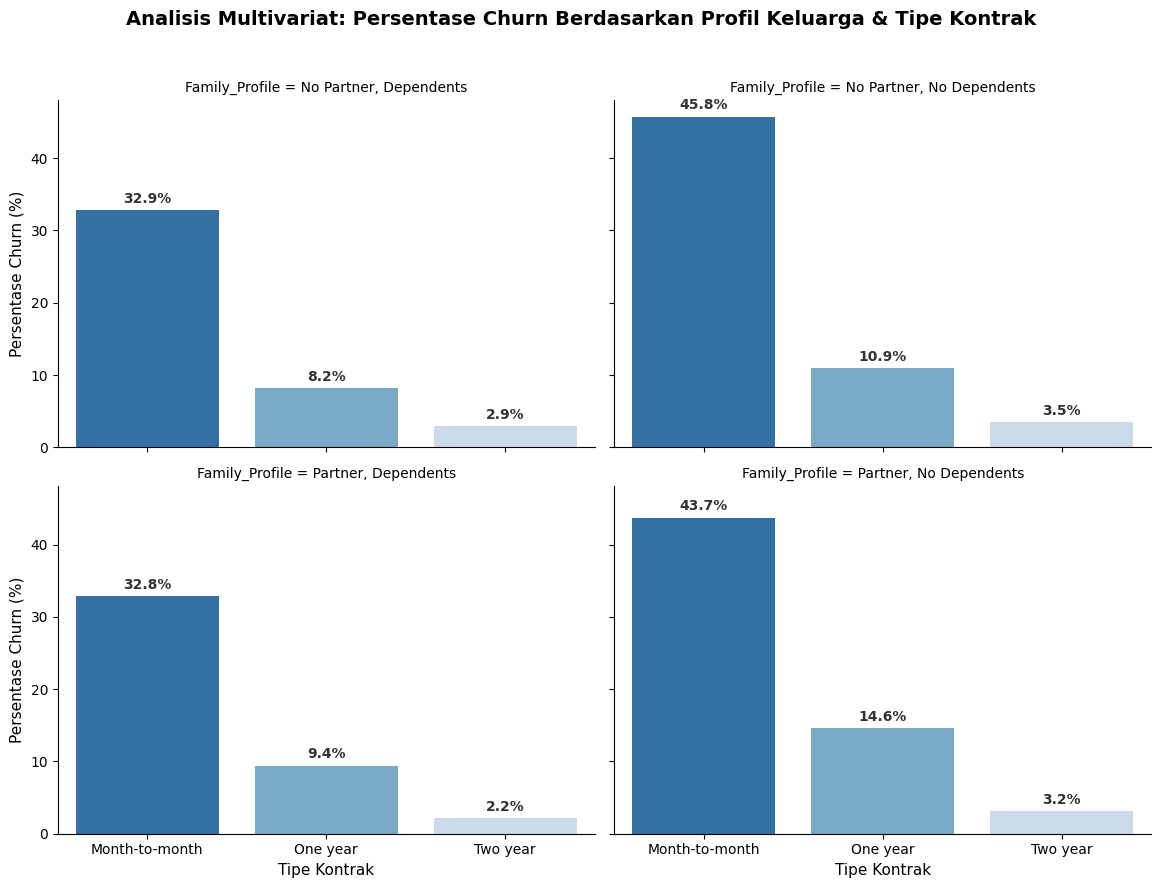

Churn                                       No   Yes
Family_Profile            Contract                  
No Partner, Dependents    Month-to-month  67.1  32.9
                          One year        91.8   8.2
                          Two year        97.1   2.9
No Partner, No Dependents Month-to-month  54.2  45.8
                          One year        89.1  10.9
                          Two year        96.5   3.5
Partner, Dependents       Month-to-month  67.2  32.8
                          One year        90.6   9.4
                          Two year        97.8   2.2
Partner, No Dependents    Month-to-month  56.3  43.7
                          One year        85.4  14.6
                          Two year        96.8   3.2

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Memastikan df terdefinisi
try:
    df
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)

# Menggunakan kolom Family_Profile yang sudah dibuat sebelumnya, atau buat kembali jika belum ada
if 'Family_Profile' not in df.columns:
    df['Family_Profile'] = 'No Partner, No Dependents'
    df.loc[(df['Partner'] == 'Yes') & (df['Dependents'] == 'No'), 'Family_Profile'] = 'Partner, No Dependents'
    df.loc[(df['Partner'] == 'No') & (df['Dependents'] == 'Yes'), 'Family_Profile'] = 'No Partner, Dependents'
    df.loc[(df['Partner'] == 'Yes') & (df['Dependents'] == 'Yes'), 'Family_Profile'] = 'Partner, Dependents'

# Menghitung persentase Churn untuk setiap kombinasi profil keluarga dan tipe kontrak
multivariate_data = df.groupby(['Family_Profile', 'Contract'])['Churn'].value_counts(normalize=True).rename('percentage').reset_index()
multivariate_data['percentage'] *= 100

# Mengambil data khusus pelanggan yang Churn (Yes) untuk dibandingkan
churn_yes_data = multivariate_data[multivariate_data['Churn'] == 'Yes']

# Visualisasi: Faceted Bar Plot
g = sns.catplot(
    data=churn_yes_data,
    x='Contract',
    y='percentage',
    col='Family_Profile',
    col_wrap=2,
    kind='bar',
    palette='Blues_r',
    height=4.5,
    aspect=1.3,
    order=['Month-to-month', 'One year', 'Two year']
)

# Mempercantik visualisasi dan menambahkan label angka di atas bar
for ax in g.axes.flat:
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom', fontsize=10, fontweight='bold', color='#333333', xytext=(0, 3),
                        textcoords='offset points')
    ax.set_ylabel('Persentase Churn (%)', fontsize=11)
    ax.set_xlabel('Tipe Kontrak', fontsize=11)

g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("Analisis Multivariat: Persentase Churn Berdasarkan Profil Keluarga & Tipe Kontrak", fontsize=14, fontweight='bold')
plt.show()

# Menampilkan ringkasan tabel kontingensi jumlah riil
summary_pivot = pd.crosstab(
    index=[df['Family_Profile'], df['Contract']],
    columns=df['Churn'],
    normalize='index'
) * 100
display(summary_pivot.round(1))

### **Interpretasi Hasil Multivariate Analysis: `Partner` vs `Dependents` vs `Contract` vs `Churn`**
* 1. Kontrak Jangka Panjang Berhasil Menekan Churn untuk Semua Profil
Bahkan untuk segmen paling rentan sekalipun, yaitu Single tanpa Tanggungan (No Partner, No Dependents), tingkat churn yang semula mencapai 45.8% pada kontrak Month-to-month berhasil ditekan secara drastis menjadi 10.9% pada kontrak 1 tahun, dan menyusut hingga 3.5% pada kontrak 2 tahun.
Hal ini menunjukkan bahwa strategi mengunci pelanggan ke dalam kontrak jangka panjang (1 atau 2 tahun) sangat efektif untuk meredam perilaku sensitif terhadap perpindahan kompetitor di seluruh profil demografis.
* 2. Month-to-Month adalah Zona Merah bagi Pelanggan Mandiri
Pelanggan tanpa tanggungan memiliki risiko churn yang luar biasa tinggi jika mereka berada di kontrak bulanan:
No Partner, No Dependents (Month-to-month): 45.8% Churn (hampir separuh pelanggan pergi).
Partner, No Dependents (Month-to-month): 43.7% Churn.
Segmen tanpa anak/tanggungan ini sangat rentan terhadap godaan promo dari kompetitor jika tidak diikat dengan kontrak jangka panjang.
* 3. Efek Keberadaan Tanggungan pada Kontrak Bulanan
Menariknya, bagi pelanggan yang memiliki tanggungan (Dependents), tingkat churn pada kontrak bulanan cenderung lebih rendah dibandingkan mereka yang tidak memiliki tanggungan:
No Partner, Dependents (Month-to-month): 32.9% Churn.
Partner, Dependents (Month-to-month): 32.8% Churn.
Kehadiran anggota keluarga/tanggungan di rumah membuat keputusan untuk bermigrasi atau memutus layanan internet/telepon menjadi lebih dipertimbangkan, bahkan ketika mereka memiliki kebebasan untuk berhenti kapan saja (kontrak bulanan).
Rekomendasi Bisnis:


---
**Rekomendasi Bisnis**

* **Kampanye Retensi Spesifik:** Lakukan kampanye proaktif untuk mengonversi pelanggan tipe No Partner, No Dependents yang saat ini menggunakan kontrak Month-to-month agar beralih ke kontrak minimal 1 tahun dengan menawarkan diskon tagihan bulanan.
* **Fokus Bundling Keluarga:** Berikan paket penawaran khusus keluarga (family plan) untuk mempertahankan loyalitas alami yang sudah terbentuk pada kelompok pelanggan dengan tanggungan.

 # **8. Ringkasan Eksekutif & Temuan Kunci EDA (Telco Customer Churn)**

Berdasarkan rangkaian analisis data eksploratif (EDA) yang telah dilakukan terhadap dataset Telco Customer Churn, berikut adalah rangkuman wawasan mendalam (*insights*) dan temuan strategis utama:

---

#### 📊 **1. Profil Umum & Karakteristik Data**
* **Ketidakseimbangan Target (*Class Imbalance*):** Proporsi pelanggan yang melakukan *Churn* adalah **26.54%** (1.869 pelanggan), sedangkan pelanggan yang bertahan (*No Churn*) mendominasi sebesar **73.46%** (5.174 pelanggan).
* **Kualitas Data:** Ditemukan *missing value* minor pada `TotalCharges` (0.16% / 11 baris) yang terjadi secara terstruktur pada pelanggan baru dengan *tenure* 0 bulan (belum sempat menghasilkan tagihan). Tidak ditemukan pencilan (*outliers*) ekstrem pada fitur numerik utama berdasarkan metode IQR.
* **Gender Tidak Berpengaruh:** Berdasarkan asosiasi *Cramer's V*, fitur `gender` memiliki korelasi mutlak **0.00** dengan target `Churn`, membuktikan bahwa jenis kelamin tidak memiliki andil dalam keputusan pelanggan untuk berhenti atau bertahan.

---

#### 🔍 **2. Pemicu Utama Churn (The Red Flags)**
* **Fase Kritis di Awal Kontrak (*Tenure* Rendah):** Mayoritas pelanggan yang *churn* pergi pada masa-masa awal berlangganan dengan median *tenure* hanya **10 bulan** (berbanding terbalik dengan pelanggan loyal yang bertahan dengan median **38 bulan**).
* **Sensitivitas Biaya Bulanan (*Monthly Charges*):** Distribusi pelanggan yang *churn* sangat padat pada kelompok tarif bulanan tinggi (**kisaran $70 - $100**). Sebaliknya, pelanggan dengan tagihan dasar yang murah (~$20) cenderung sangat loyal.
* **Zona Merah Kontrak Bulanan (*Month-to-Month*):** Jenis kontrak memiliki asosiasi paling kuat terhadap *churn* (Cramer's V: **0.41**). Pelanggan dengan kontrak bulanan memiliki tingkat *churn* ekstrem mencapai **42.7%**.
* **Anomali Layanan Premium (Fiber Optic):** Pengguna internet **Fiber optic** (layanan premium/lebih mahal) justru memiliki tingkat *churn* yang sangat tinggi yaitu **41.9%**, jauh lebih tinggi dibanding pengguna DSL (**19.0%**).

---

#### 🏡 **3. Faktor Demografis & Kekuatan Hubungan Keluarga**
* **Profil Keluarga sebagai Jangkar Loyalitas:** Pelanggan yang memiliki tanggungan (`Dependents`) dan pasangan (`Partner`) memiliki tingkat loyalitas paling tinggi dengan angka *churn* terendah (**14.2%**). Ikatan kebutuhan rumah tangga bersama membuat keputusan bermigrasi menjadi lebih sulit.
* **Kerentanan Pelanggan Mandiri (Single):** Sebaliknya, kelompok pelanggan mandiri tanpa pasangan dan tanpa tanggungan (*No Partner, No Dependents*) merupakan kelompok paling tidak stabil dengan tingkat *churn* tertinggi (**34.2%**).

---

#### 🎯 **4. Interaksi Multivariat (Temuan Paling Kritis)**
Ketika kita membedah interaksi antara profil keluarga, tipe kontrak, dan keputusan *churn*, kita menemukan:
1. **Efek Penyelamat dari Kontrak Jangka Panjang:** Strategi penguncian kontrak 1 atau 2 tahun terbukti **sangat sukses meredam risiko churn di semua segmen demografis**. Bahkan untuk kelompok paling rentan (*Single tanpa tanggungan*), angka *churn* yang semula **45.8%** di kontrak bulanan langsung anjlok menjadi **10.9%** (kontrak 1 tahun) dan hanya **3.5%** (kontrak 2 tahun).
2. **Kekuatan Proteksi Alami Keluarga:** Kehadiran anggota keluarga/tanggungan di rumah memberikan perlindungan retensi alami, bahkan saat mereka berada dalam fleksibilitas kontrak bulanan (*Month-to-month*), dengan tingkat *churn* yang berkurang dari ~45.8% ke ~32.8%.

---

#### 💡 **Rekomendasi Bisnis Berbasis Data (Actionable Insights)**
1. **Insentif Migrasi Kontrak:** Prioritaskan kampanye pemasaran proaktif untuk menawarkan potongan harga atau benefit tambahan bagi pelanggan *Month-to-month* (khususnya segmen *Single*) agar bersedia bermigrasi ke kontrak minimal 1 atau 2 tahun.
2. **Paket Khusus Keluarga (*Family Bundling*):** Buatlah skema penawaran *bundling* berbasis keluarga (misalnya diskon untuk penambahan anggota baru atau kuota rumah tangga bersama) untuk mengunci loyalitas alami kelompok pelanggan yang memiliki tanggungan.
3. **Audit Kualitas Layanan Fiber Optic:** Lakukan investigasi teknis dan layanan pelanggan mendalam pada segmen internet *Fiber optic* untuk mendeteksi mengapa pelanggan premium dengan biaya tinggi ini sangat rentan untuk melakukan *churn* (apakah karena isu stabilitas koneksi, ekspektasi harga, atau buruknya penanganan gangguan teknis).



---



# **Preprocessing**
## **1. Pemeriksaan Ulang Dataset**

In [ ]:
import pandas as pd

# Membaca ulang dataset dari URL karena variabel 'df' belum terdefinisi di session ini
url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
df = pd.read_csv(url)

# 1. Pemeriksaan tipe data dan missing value menggunakan info()
print("=== Tipe Data dan Missing Value (Ringkasan) ===")
print(df.info())

# 2. Pemeriksaan jumlah missing value secara detail per kolom
print("\n=== Jumlah Missing Value Per Kolom ===")
missing_values = df.isna().sum()
missing_percentage = (df.isna().mean() * 100).round(2)
df_missing = pd.DataFrame({
    'Banyak Missing': missing_values,
    'Persentase (%)': missing_percentage
})
print(df_missing)

# 3. Pemeriksaan jumlah baris duplikat
print("\n=== Jumlah Baris Duplikat ===")
duplicate_rows = df.duplicated().sum()
print(f"Jumlah baris duplikat dalam dataset: {duplicate_rows}")

=== Tipe Data dan Missing Value (Ringkasan) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 

**Interpretasi**:
* Kolom `TotalCharges` memiliki **11 *missing value*** (sekitar **0.16%** dari total data).
* Kolom-kolom lainnya bersih dari *missing value* (**0%**).
* Tidak ditemukan adanya baris duplikat **(0 duplikat)** di dalam dataset ini, yang berarti setiap baris data bersifat unik.

In [ ]:
unique_types = pd.DataFrame({
    'Tipe Data': df.dtypes,
    'Jumlah Unique Value': df.nunique()
}).sort_values('Jumlah Unique Value')

display(unique_types)

,Tipe Data,Jumlah Unique Value
gender,object,2
SeniorCitizen,int64,2
Partner,object,2
Dependents,object,2
PhoneService,object,2
PaperlessBilling,object,2
Churn,object,2
MultipleLines,object,3
TechSupport,object,3
StreamingTV,object,3


Interpretasi:
* Variabel Kategorikal/Biner (2 - 4 nilai unik): Kolom seperti `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, dan `Churn` memiliki tepat 2 nilai unik. Kolom layanan tambahan (seperti `MultipleLines`, `OnlineSecurity`, dll.) memiliki 3 nilai unik, dan `PaymentMethod` memiliki 4 nilai unik.
* Variabel Numerik/Kontinu (>70 nilai unik): Kolom `tenure` memiliki 73 nilai unik (merepresentasikan bulan), sementara `MonthlyCharges` (1.585) dan `TotalCharges` (6.530) memiliki variasi nilai yang sangat tinggi.
* Kolom Identitas: Kolom `customerID` memiliki 7.043 nilai unik yang menandakan bahwa setiap baris data mewakili satu pelanggan unik.

# **2. Data Cleaning and Domain Validation**

In [ ]:
# Memeriksa baris pada kolom numerik yang memiliki nilai non-numeric atau spasi kosong
print("=== Memeriksa Nilai Non-Numerik / Spasi Kosong ===")

# Kolom yang seharusnya numerik
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    # Mencoba mengonversi ke numerik dengan coerce, lalu mencari nilai yang menjadi NaN baru
    # Ini berguna untuk mendeteksi string kosong seperti " " atau karakter non-angka lainnya
    converted = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')
    invalid_rows = df[df[col].astype(str).str.strip() == ""]

    print(f"\nFitur '{col}':")
    print(f" - Jumlah baris dengan string kosong/spasi: {len(invalid_rows)}")
    if len(invalid_rows) > 0:
        display(invalid_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

=== Memeriksa Nilai Non-Numerik / Spasi Kosong ===

Fitur 'tenure':
 - Jumlah baris dengan string kosong/spasi: 0

Fitur 'MonthlyCharges':
 - Jumlah baris dengan string kosong/spasi: 0

Fitur 'TotalCharges':
 - Jumlah baris dengan string kosong/spasi: 0


**Interpretasi**: Ternyata **tidak terdapat** baris yang memiliki nilai masukan yang tidak sesuai dengan tipe data variabel yang seharusnya.

## **2.1 Feature dan Target Separation**

In [ ]:
import pandas as pd

# Memastikan data dimuat ulang jika variabel df belum ada di session
try:
    df_prep = df.copy()
except NameError:
    url = "https://raw.githubusercontent.com/rapiissan/PROJECT-DSMBC/refs/heads/main/telco_customer_churn%20-%20telco_customer_churn.csv"
    df = pd.read_csv(url)
    df_prep = df.copy()

# pisahkan predictor (X) dan target (y)
TARGET = "Churn"
X = df_prep.drop(columns=[TARGET])
y = df_prep[TARGET]

# cek ukuran data dan proporsi kelas target
print("Shape feature:", X.shape)
print("Shape target:", y.shape)
display((y.value_counts(normalize=True) * 100).round(2).to_frame("persen"))

Shape feature: (7043, 20)
Shape target: (7043,)


,persen
Churn,
No,73.46
Yes,26.54


<div style="text-align: justify; line-height: 1.65;">Data bersih berisi 7043 observasi dan 20 predictor. Kelas 0 mencakup 73,46 persen dan kelas 1 sebesar 26,54 persen,
sehingga split memakai stratification.</div>

## **2.2 Mengatasi missing value**
Missing value terdapat pada variabel `TotalCharges` dengan `tenure = 0`.

=== Verifikasi Jumlah Missing Value Setelah Imputasi ===
Missing value di df_prep['TotalCharges']: 0
Missing value di X['TotalCharges']: 0


##